# SignatureAI — Hugging Face ZIP → Safe Cleaning → T4 RT-DETRv2 → Early Stopping → Comet + S3

**Colab T4 GPU | RT-DETRv2-R18 (Apache-2.0, no Ultralytics) | reusable versioned model artifacts**

The notebook downloads `merged_signature_dataset.zip` **directly** from your Hugging Face dataset repository, pinned to its resolved commit; safely extracts it; reads COCO or YOLO `.txt` labels; checks annotation validity, SHA-256 duplicates, pHash/SSIM candidates and cross-split leakage; trains RT-DETRv2 with **mixed precision, gradient accumulation and early stopping**; logs epoch metrics to Comet; then stores the best checkpoint as an immutable Amazon S3 version with checksums and optional future reload.

**Default T4 settings:** 640×640, microbatch **2**, accumulate **4** (= effective batch size 8), **up to 20 epochs**, early stopping on **validation mAP@50** with patience **4** and minimum improvement **0.001**, minimum **5** epochs. If CUDA OOM occurs, change to `BATCH_SIZE=1` and `GRAD_ACCUM=8` and rerun starting from the model/data-loader cells. These are safe starting points, not guaranteed runtimes or scores.

**Dataset size warning:** Hugging Face reports this ZIP as approximately **3.5 GB** (compressed). Ensure Colab has enough free disk for the downloaded ZIP **plus** extracted files and processed copies. This notebook checks available disk before extraction. Free Colab T4 sessions have variable GPU availability and time limits. Consider a small smoke test first.

**Credentials:** Colab Secrets (key icon) → `COMET_API_KEY`, `AWS_S3_BUCKET`, `AWS_REGION`, `AWS_ACCESS_KEY_ID`, `AWS_SECRET_ACCESS_KEY`. Optionally `COMET_WORKSPACE`, `HF_TOKEN` (if access is restricted) or `AWS_SESSION_TOKEN`. Grant notebook access to each secret. Never paste secrets into code or commit weights to GitHub.

**Limitations:** The notebook trains **signature object detection**, NOT signature identity/similarity. It doesn't deploy Redis/Celery/FastAPI, perform load testing, or implement automatic remote retraining on dataset updates. Dataset-specific execution and actual GPU training have **not** been verified here. Writer-level isolation requires writer/document group metadata when available.


In [1]:
%pip -q install "transformers>=4.50,<5" "accelerate>=0.32" "torchmetrics[detection]>=1.4" pycocotools scikit-image pandas matplotlib pillow pyyaml boto3 comet_ml huggingface_hub hf-xet -q


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [41]:
# CONFIG: T4 GPU + direct Hugging Face dataset download.
from pathlib import Path

ZIP_SOURCE = 'huggingface'  # 'huggingface' (default), 'upload', or 'drive'
HF_DATASET_REPO = 'netsol-signature-detection/Signature-Detection-System'
HF_ZIP_FILENAME = 'merged_signature_dataset.zip'
HF_REVISION = 'main'       # auto-resolve to immutable commit SHA before downloading
DRIVE_ZIP_PATH = '/content/drive/MyDrive/signature_dataset.zip'
SAVE_TO_DRIVE = False      # optional extra backup (S3 remains primary)
DRIVE_OUTPUT_DIR = '/content/drive/MyDrive/SignatureAI_Runs'

MODEL_ID = 'PekingU/rtdetr_v2_r18vd'  # Apache-2.0
KEEP_CLASSES = ['signature']  # use None if your dataset intentionally contains other classes
IMAGE_SIZE = 640
SEED = 42
RATIOS = (0.80, 0.10, 0.10)
PHASH_THRESHOLD = 4
SSIM_THRESHOLD = 0.995
NEAR_CROP_SSIM_THRESHOLD = 0.97
MAX_NEAR_PAIRS = 20000
GROUP_METADATA_CSV = None           # e.g. 'group_metadata.csv' inside ZIP
REQUIRE_GROUP_METADATA = False      # set True if writer/document isolation is mandatory

# T4 16GB VRAM: conservative starting configuration (microbatch=2).
# On out-of-memory: BATCH_SIZE=1 and GRAD_ACCUM=8, then recreate model + data loaders.
BATCH_SIZE = 8
GRAD_ACCUM = 1                # effective batch size = 8
EPOCHS = 5                   # upper limit; early stopping can stop earlier
LR = 2e-5
NUM_WORKERS = 4
SCORE_THRESHOLD = 0.05
EARLY_STOPPING = True
EARLY_STOPPING_METRIC = 'val_map50'
EARLY_STOPPING_PATIENCE = 2
EARLY_STOPPING_MIN_DELTA = 0.001
EARLY_STOPPING_MIN_EPOCHS = 2

USE_COMET = True
COMET_PROJECT = 'signature-ai-detection'
UPLOAD_TO_S3 = True
S3_PREFIX = 'signatureai/detection'
S3_UPDATE_LATEST_ALIAS = True
UPLOAD_TO_R2 = False             # optional secondary storage
PROMOTE_TO_PRODUCTION = False    # never auto-promote from this training notebook
RELOAD_FROM_S3 = True          # optional checksum-verified reload demonstration

WORKDIR = Path('/content/signature_ai_work')
RAW_DIR = WORKDIR / 'raw'
RUN_DIR = WORKDIR / 'run'
REPORTS_DIR = RUN_DIR / 'reports'
CLEAN_DIR = RUN_DIR / 'cleaned_coco'
MODEL_DIR = RUN_DIR / 'best_model'

assert BATCH_SIZE >= 1 and GRAD_ACCUM >= 1 and EPOCHS >= 1
assert EARLY_STOPPING_PATIENCE >= 1 and EARLY_STOPPING_MIN_EPOCHS >= 1
assert EARLY_STOPPING_METRIC in {'val_map50', 'val_map'}
print('T4 training config | microbatch:', BATCH_SIZE,
      '| accumulation:', GRAD_ACCUM,
      '| effective:', BATCH_SIZE * GRAD_ACCUM,
      '| max epochs:', EPOCHS,
      '| early stopping:', EARLY_STOPPING)


T4 training config | microbatch: 8 | accumulation: 1 | effective: 8 | max epochs: 5 | early stopping: True


In [3]:
import os, io, sys, json, csv, time, math, random, shutil, zipfile, hashlib, warnings
from collections import defaultdict, Counter
from pathlib import Path
import numpy as np, pandas as pd, cv2, yaml
from PIL import Image, ImageEnhance, ImageFile
from skimage.metrics import structural_similarity
from IPython.display import display

random.seed(SEED); np.random.seed(SEED)
for d in [WORKDIR, RAW_DIR, RUN_DIR, REPORTS_DIR, CLEAN_DIR, MODEL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

def write_csv(name, rows, fields=None):
    p = REPORTS_DIR / name
    if fields is None: fields = sorted(set().union(*(r.keys() for r in rows))) if rows else ['note']
    with p.open('w', newline='', encoding='utf-8') as f:
        w = csv.DictWriter(f, fieldnames=fields, extrasaction='ignore'); w.writeheader(); w.writerows(rows)
    print(f'Wrote {p} ({len(rows)} rows)')

def sha256_file(path, chunk_size=4*1024*1024):
    h=hashlib.sha256()
    with open(path, 'rb') as f:
        while True:
            block=f.read(chunk_size)
            if not block: break
            h.update(block)
    return h.hexdigest()

def save_json(path, obj):
    Path(path).write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str), encoding='utf-8')
# Unique run identifier, saved in S3 and Comet. Each run must get a new version.
import datetime, uuid
RUN_VERSION = 'v' + datetime.datetime.now(datetime.timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '-' + uuid.uuid4().hex[:8]
print('New training run version:', RUN_VERSION)

# Check secrets BEFORE consuming training GPU time. Never print secret values.
if USE_COMET or UPLOAD_TO_S3 or UPLOAD_TO_R2:
    from google.colab import userdata
    def secret_or_none(name):
        try: return userdata.get(name)
        except Exception: return None
    if USE_COMET and not secret_or_none('COMET_API_KEY'):
        raise RuntimeError('COMET_API_KEY secret missing. Colab left sidebar > Secrets > add and grant access.')
    if UPLOAD_TO_S3:
        required = ['AWS_S3_BUCKET','AWS_REGION','AWS_ACCESS_KEY_ID','AWS_SECRET_ACCESS_KEY']
        missing = [k for k in required if not secret_or_none(k)]
        if missing: raise RuntimeError('Amazon S3 secret(s) missing: '+', '.join(missing))
    if UPLOAD_TO_R2:
        required = ['R2_ENDPOINT','R2_ACCESS_KEY','R2_SECRET_KEY','R2_BUCKET']
        missing = [k for k in required if not secret_or_none(k)]
        if missing: raise RuntimeError('R2 secret(s) missing: '+', '.join(missing))
print('Secret preflight: OK (credentials not displayed).')

# Hugging Face provenance (populated only for ZIP_SOURCE='huggingface').
HF_RESOLVED_COMMIT = None
HF_DATASET_URI = None


New training run version: v20261109T142002Z-8a4d7444
Secret preflight: OK (credentials not displayed).


In [4]:
# ZIP ingestion and safe extraction. Default source: your Hugging Face dataset repo.
# hf_hub_download is used (NOT load_dataset, which is not appropriate for a giant ZIP).
if ZIP_SOURCE == 'huggingface':
    from huggingface_hub import HfApi, hf_hub_download
    from google.colab import userdata
    try:
        hf_token = userdata.get('HF_TOKEN')
    except Exception:
        hf_token = None
    api = HfApi(token=hf_token)
    info = api.repo_info(repo_id=HF_DATASET_REPO, repo_type='dataset', revision=HF_REVISION)
    HF_RESOLVED_COMMIT = info.sha
    HF_DATASET_URI = f'https://huggingface.co/datasets/{HF_DATASET_REPO}/tree/{HF_RESOLVED_COMMIT}'
    print('Pinned Hugging Face dataset commit:', HF_RESOLVED_COMMIT)
    zip_path = Path(hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=HF_ZIP_FILENAME,
        repo_type='dataset',
        revision=HF_RESOLVED_COMMIT,
        token=hf_token,
        local_dir='/content/signatureai_hf_download',
    ))
elif ZIP_SOURCE == 'drive':
    from google.colab import drive
    drive.mount('/content/drive')
    zip_path = Path(DRIVE_ZIP_PATH)
    assert zip_path.is_file(), f'ZIP not found: {zip_path}'
elif ZIP_SOURCE == 'upload':
    from google.colab import files
    uploaded = files.upload()
    candidates = [Path('/content') / name for name in uploaded if name.lower().endswith('.zip')]
    assert len(candidates) == 1, 'Upload exactly one .zip file.'
    zip_path = candidates[0]
else:
    raise ValueError("ZIP_SOURCE must be 'huggingface', 'upload' or 'drive'")

print('Dataset ZIP:', zip_path, '| GB:', round(zip_path.stat().st_size / 1e9, 2))
assert zipfile.is_zipfile(zip_path), 'Downloaded path is not a valid ZIP archive.'

# Fresh run: never combine stale images or checkpoints from previous runs.
for old in (RAW_DIR, RUN_DIR):
    if old.exists(): shutil.rmtree(old)
for d in (RAW_DIR, RUN_DIR, REPORTS_DIR, CLEAN_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Reject zip-slip and symlink entries, keep bounded file counts/sizes.
MAX_UNPACKED_BYTES = 25 * 1024**3
MAX_FILES = 250000
with zipfile.ZipFile(zip_path) as z:
    members = [m for m in z.infolist() if not m.is_dir()]
    declared_unpacked = sum(m.file_size for m in members)
    if len(members) > MAX_FILES or declared_unpacked > MAX_UNPACKED_BYTES:
        raise ValueError('ZIP exceeds safety limits; inspect its contents before increasing limits.')
    # The pipeline also makes processed copies. Warn about realistic disk needs in Colab.
    free_bytes = shutil.disk_usage(WORKDIR).free
    estimated_required = 2 * declared_unpacked + 2 * 1024**3
    print('Declared uncompressed GB:', round(declared_unpacked/1e9,2),
          '| free disk GB:', round(free_bytes/1e9,2),
          '| estimated extra GB (raw + cleaned + headroom):', round(estimated_required/1e9,2))
    if estimated_required > free_bytes:
        raise RuntimeError('Not enough Colab disk to extract AND copy cleaned images safely. Free disk or use higher-disk runtime.')
    base = RAW_DIR.resolve()
    for member in members:
        destination = (RAW_DIR / member.filename).resolve()
        if destination != base and base not in destination.parents:
            raise ValueError(f'Unsafe ZIP path: {member.filename}')
        if (member.external_attr >> 16) & 0o170000 == 0o120000:
            raise ValueError(f'Symlink ZIP entry not allowed: {member.filename}')
    z.extractall(RAW_DIR)

print('Extracted files:', len(members))
if HF_RESOLVED_COMMIT:
    save_json(REPORTS_DIR/'huggingface_dataset_source.json', {
        'repo_id': HF_DATASET_REPO,
        'file': HF_ZIP_FILENAME,
        'revision_requested': HF_REVISION,
        'revision_resolved': HF_RESOLVED_COMMIT,
        'source_uri': HF_DATASET_URI,
        'downloaded_zip_bytes': zip_path.stat().st_size,
    })


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Pinned Hugging Face dataset commit: df9b41c444b3ee327648acbfb48f3523cac173ba


merged_signature_dataset.zip:   0%|          | 0.00/3.50G [00:00<?, ?B/s]

Dataset ZIP: /content/signatureai_hf_download/merged_signature_dataset.zip | GB: 3.5
Declared uncompressed GB: 3.73 | free disk GB: 117.09 | estimated extra GB (raw + cleaned + headroom): 9.6
Extracted files: 57919


## Dataset format detection

Supported layouts:
- Roboflow COCO: `train/_annotations.coco.json`, `valid/_annotations.coco.json`, `test/_annotations.coco.json` and images.
- Standard COCO: image records, annotations and categories in `instances_*.json`.
- YOLO: `images/*.jpg` + matching `labels/*.txt`, with optional `data.yaml` class names. Split folders optional.

**Not supported without conversion:** segmentation polygons without bounding boxes, unlabeled images, cropped signatures with only writer IDs, Pascal VOC XML, detection annotations in a different schema.

In [5]:
IMAGE_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}
ALL_IMAGES = sorted(p for p in RAW_DIR.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXT and '__MACOSX' not in p.parts)
assert ALL_IMAGES, 'No image files found in ZIP.'
image_name_idx = defaultdict(list)
for p in ALL_IMAGES: image_name_idx[p.name].append(p)

def source_split(path):
    for part in reversed(Path(path).parts):
        p = part.lower()
        if p in {'train', 'training'}: return 'train'
        if p in {'valid', 'val', 'validation', 'dev'}: return 'valid'
        if p in {'test', 'testing'}: return 'test'
    return None

def resolve_image(json_path, image_name):
    name = str(image_name).replace('\\', '/')
    cands = [json_path.parent / name, RAW_DIR / name, json_path.parent / Path(name).name,
             json_path.parent / 'images' / Path(name).name]
    for candidate in cands:
        if candidate.is_file() and candidate.suffix.lower() in IMAGE_EXT: return candidate.resolve()
    matches = image_name_idx.get(Path(name).name, [])
    if len(matches) == 1: return matches[0].resolve()
    return None

def find_coco_json():
    found = []
    for p in RAW_DIR.rglob('*.json'):
        if '__MACOSX' in p.parts: continue
        try:
            with p.open(encoding='utf-8') as f: j = json.load(f)
            if isinstance(j, dict) and isinstance(j.get('images'), list) and isinstance(j.get('annotations'), list) and isinstance(j.get('categories'), list):
                found.append((p, j))
        except (OSError, ValueError, UnicodeError): pass
    return found

COCO_FILES = find_coco_json()
records = []
issues = []
class_names = set()

if COCO_FILES:
    FORMAT = 'COCO'
    for jp, cj in COCO_FILES:
        split = source_split(jp) or ('train' if 'train' in jp.name.lower() else 'test' if 'test' in jp.name.lower() else 'valid' if 'val' in jp.name.lower() else None)
        categories = {int(c['id']): str(c['name']) for c in cj['categories']}
        ann_by_img = defaultdict(list)
        for a in cj['annotations']:
            if 'bbox' not in a or len(a['bbox']) != 4:
                issues.append({'file': str(jp), 'issue': 'COCO polygon/no bbox skipped', 'image_id': a.get('image_id')}); continue
            if int(a.get('iscrowd', 0)) == 1: continue
            cls = categories.get(int(a['category_id']))
            if cls is None:
                issues.append({'file': str(jp), 'issue': 'Unknown COCO category', 'image_id': a.get('image_id')}); continue
            ann_by_img[a['image_id']].append({'class_name': cls, 'bbox': list(map(float, a['bbox']))})
            class_names.add(cls)
        for im in cj['images']:
            path = resolve_image(jp, im['file_name'])
            if path is None:
                issues.append({'file': str(jp), 'issue': f'Missing or ambiguous image: {im["file_name"]}'})
                continue
            records.append({'path': path, 'split': split or source_split(path), 'annotations': ann_by_img[im['id']],
                            'source': str(jp)})
else:
    FORMAT = 'YOLO'
    yaml_paths = sorted([p for p in RAW_DIR.rglob('*.yaml') if p.name.lower() in {'data.yaml','dataset.yaml'}] +
                        [p for p in RAW_DIR.rglob('*.yml') if p.name.lower() in {'data.yml','dataset.yml'}])
    id_to_name = {}
    if yaml_paths:
        data_yaml = yaml.safe_load(yaml_paths[0].read_text(encoding='utf-8')) or {}
        names = data_yaml.get('names', [])
        id_to_name = {int(k): str(v) for k,v in names.items()} if isinstance(names,dict) else {i:str(v) for i,v in enumerate(names)}
    else:
        text_files = list(RAW_DIR.rglob('classes.txt'))
        if text_files:
            id_to_name = {i:x.strip() for i,x in enumerate(text_files[0].read_text().splitlines()) if x.strip()}
    labelled_count = 0
    for path in ALL_IMAGES:
        rel = path.relative_to(RAW_DIR)
        parts = list(path.parts)
        candidates = []
        if 'images' in parts:
            i = len(parts)-1 - parts[::-1].index('images')
            new = parts.copy(); new[i] = 'labels'
            candidates.append(Path(*new).with_suffix('.txt'))
        candidates += [path.with_suffix('.txt'), path.parent.parent / 'labels' / (path.stem+'.txt')]
        lp = next((p for p in candidates if p.is_file()), None)
        boxes = []
        if lp is not None:
            labelled_count += 1
            for line_num, line in enumerate(lp.read_text(encoding='utf-8-sig').splitlines(), 1):
                fields = line.split()
                if not fields: continue
                if len(fields) != 5:
                    issues.append({'file':str(lp), 'issue': f'YOLO label line {line_num} has {len(fields)} fields; expected 5'}); continue
                try:
                    cls_id = int(fields[0]); xc, yc, w, h = map(float, fields[1:])
                    if cls_id < 0 or not all(map(math.isfinite, (xc,yc,w,h))): raise ValueError()
                    cls = id_to_name.get(cls_id, f'class_{cls_id}')
                    boxes.append({'class_name': cls, 'bbox_normalized_yolo': [xc,yc,w,h]})
                    class_names.add(cls)
                except ValueError:
                    issues.append({'file':str(lp), 'issue': f'Invalid YOLO label at line {line_num}'})
        records.append({'path':path.resolve(), 'split':source_split(path), 'annotations':boxes, 'source':str(lp) if lp else ''})
    if labelled_count == 0:
        raise ValueError('No COCO JSON or YOLO TXT labels found. A detection model needs bounding-box annotations.')

# Unique path records: some ZIP exports include multiple references to same image.
merged = {}
for rec in records:
    key = str(rec['path'])
    if key not in merged: merged[key] = rec
    elif merged[key]['annotations'] != rec['annotations']:
        issues.append({'file':key, 'issue':'Image listed twice with different annotations; first record used'})
records = list(merged.values())
if KEEP_CLASSES is not None:
    allowed = {x.casefold() for x in KEEP_CLASSES}
    for r in records: r['annotations'] = [a for a in r['annotations'] if a['class_name'].casefold() in allowed]
    class_names = {a['class_name'] for r in records for a in r['annotations']}
assert records and class_names, 'No labeled objects found; please inspect annotations / KEEP_CLASSES.'
label_names = sorted(class_names)
label2id = {name:i for i,name in enumerate(label_names)}
id2label = {i:name for name,i in label2id.items()}
write_csv('annotation_parsing_issues.csv', issues)
print('Format:', FORMAT, '| Images:', len(records), '| Classes:', label_names)
print('Existing split counts:', dict(Counter(r['split'] or 'unsplit' for r in records)))

Wrote /content/signature_ai_work/run/reports/annotation_parsing_issues.csv (0 rows)
Format: YOLO | Images: 28958 | Classes: ['signature']
Existing split counts: {'test': 2718, 'train': 22953, 'valid': 3287}


## Image validation + conservative duplicate screening

- **Exact duplicates**: matching decoded pixels are removed; conflicting labels cause quarantine. Cross-split exact conflicts are separately logged in `exact_cross_split_leakage.csv`.
- **Near duplicates**: first pHash candidate screening; then require both whole-image SSIM **and signature bounding-box crop SSIM** for labeled images, to avoid treating two different signatures on the same blank document template as a duplicate. Pairs with missing/incompatible annotations but almost identical image content are quarantined for human review. Near-duplicates are **not deleted automatically**.
- **Identity/document leakage**: optionally supply `group_metadata.csv` with `path,group_id`, grouping all related images together. Without reliable IDs, writer/document leakage cannot be ruled out from pixels alone.
- **Audit**: suspected groups, actions, and final leakage assertions are written to CSV/JSON. Thresholds are heuristics; manually inspect a sample of near matches.


In [6]:
# Image validation, YOLO conversion, bounding box sanity checks.
valid_records = []
invalid_images, bad_boxes = [], []
for i, r in enumerate(records):
    p = r['path']
    try:
        with Image.open(p) as im:
            im.load()
            width, height = im.size
            if width < 32 or height < 32: raise ValueError('image smaller than 32px')
            # Do not EXIF-rotate without similarly rotating annotation boxes.
            if im.getexif().get(274, 1) not in {1, None}:
                raise ValueError('EXIF rotation present: needs bbox-aware correction')
            rgb = np.asarray(im.convert('RGB'))
    except Exception as e:
        invalid_images.append({'path':str(p), 'reason':repr(e)}); continue
    boxes = []
    has_invalid_bbox = False
    for a in r['annotations']:
        if 'bbox_normalized_yolo' in a:
            xc,yc,w,h = a['bbox_normalized_yolo']; box = [(xc-w/2)*width, (yc-h/2)*height, w*width, h*height]
        else:
            box = a['bbox']
        x,y,w,h = box
        if not all(math.isfinite(v) for v in box) or w<=0 or h<=0 or x < -0.5 or y < -0.5 or x+w>width+0.5 or y+h>height+0.5:
            bad_boxes.append({'path':str(p),'class':a['class_name'],'bbox':str(box), 'reason':'out of bounds / invalid'})
            has_invalid_bbox = True
            continue
        x=max(0.0,x); y=max(0.0,y); w=min(w,width-x); h=min(h,height-y)
        boxes.append({'class_name':a['class_name'], 'bbox':[float(x),float(y),float(w),float(h)]})
    if has_invalid_bbox:
        invalid_images.append({'path':str(p), 'reason':'Quarantined: at least one invalid bounding box'})
        continue
    r = {**r, 'width':width, 'height':height, 'annotations':boxes}
    # Decoded-pixel digest catches identical pixels even when PNG/JPEG files differ in metadata.
    r['pixel_sha256'] = hashlib.sha256(f'{width}x{height}|'.encode()+rgb.tobytes()).hexdigest()
    r['file_sha256'] = hashlib.sha256(p.read_bytes()).hexdigest()
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    small = cv2.resize(gray, (32,32), interpolation=cv2.INTER_AREA).astype(np.float32)
    dct = cv2.dct(small)[:8,:8]
    med = np.median(dct.flatten()[1:])
    r['phash'] = sum(int(v > med) << j for j,v in enumerate(dct.flatten()))
    valid_records.append(r)

write_csv('invalid_images.csv',invalid_images)
write_csv('bad_bounding_boxes.csv',bad_boxes)
if bad_boxes:
    print('WARNING: images with invalid bounding boxes quarantined. Review and re-annotate them.')

# Exact duplicate groups. Conflicting annotations are quarantined, not guessed away.
by_sha = defaultdict(list)
for r in valid_records: by_sha[r['pixel_sha256']].append(r)
exact_rows, conflict_rows, unique_records = [], [], []
exact_cross_rows = []
priority = {'test':3,'valid':2,'train':1,None:0}
def annotation_signature(r):
    return sorted((a['class_name'], *(round(z,1) for z in a['bbox'])) for a in r['annotations'])
for digest, group in by_sha.items():
    if len(group) == 1:
        unique_records.append(group[0]); continue
    if len({tuple(annotation_signature(g)) for g in group}) > 1:
        conflict_rows.extend({'sha256':digest,'path':str(x['path']), 'issue':'Conflicting labels on identical pixels'} for x in group)
        continue
    group.sort(key=lambda r:(priority.get(r['split'],0),str(r['path'])),reverse=True)
    keep = group[0]; unique_records.append(keep)
    for drop in group[1:]:
        if drop['split'] != keep['split']:
            exact_cross_rows.append({'kept':str(keep['path']), 'kept_split':keep['split'] or 'unsplit',
                                     'removed':str(drop['path']), 'removed_split':drop['split'] or 'unsplit',
                                     'sha256':digest, 'resolution':'removed identical copy'})
        exact_rows.append({'kept':str(keep['path']), 'removed':str(drop['path']),
                           'original_split':drop['split'], 'sha256':digest})
write_csv('exact_duplicates_removed.csv',exact_rows)
write_csv('exact_cross_split_leakage.csv',exact_cross_rows)
write_csv('quarantined_conflicting_duplicates.csv',conflict_rows)
if not unique_records: raise ValueError('No valid images remain after validation/deduplication.')
print('After validation/exact dedupe:',len(unique_records),'| exact removed:',len(exact_rows),'| label conflicts quarantined:',len(conflict_rows))

Wrote /content/signature_ai_work/run/reports/invalid_images.csv (0 rows)
Wrote /content/signature_ai_work/run/reports/bad_bounding_boxes.csv (0 rows)
Wrote /content/signature_ai_work/run/reports/exact_duplicates_removed.csv (0 rows)
Wrote /content/signature_ai_work/run/reports/exact_cross_split_leakage.csv (0 rows)
Wrote /content/signature_ai_work/run/reports/quarantined_conflicting_duplicates.csv (0 rows)
After validation/exact dedupe: 28958 | exact removed: 0 | label conflicts quarantined: 0


In [7]:

# ============================================================
# SIGNATUREAI: SCALABLE NEAR-DUPLICATE + LEAKAGE SCREENING
# Designed for large datasets (~57,000 images)
# Uses document pHash + signature-region pHash + SSIM
# Retains DSU groups for the next leakage-prevention cell
# ============================================================

from collections import Counter
from functools import lru_cache

CROP_PHASH_THRESHOLD = 14
MAX_SSIM_COMPARISONS = 100000


# ------------------------------------------------------------
# 1. BK-TREE FOR FAST HAMMING-DISTANCE SEARCH
# ------------------------------------------------------------

class BKTree:
    def __init__(self):
        self.root = None

    def add(self, value, idx):
        if self.root is None:
            self.root = [value, [idx], {}]
            return

        node = self.root

        while True:
            dist = (value ^ node[0]).bit_count()

            if dist == 0:
                node[1].append(idx)
                return

            if dist in node[2]:
                node = node[2][dist]
            else:
                node[2][dist] = [value, [idx], {}]
                return

    def query(self, value, radius):
        if self.root is None:
            return []

        results = []
        stack = [self.root]

        while stack:
            node = stack.pop()
            dist = (value ^ node[0]).bit_count()

            if dist <= radius:
                results.extend(
                    (idx, dist) for idx in node[1]
                )

            for edge, child in node[2].items():
                if dist - radius <= edge <= dist + radius:
                    stack.append(child)

        return results


# ------------------------------------------------------------
# 2. DISJOINT SET UNION FOR DUPLICATE GROUPING
# ------------------------------------------------------------

class DSU:
    def __init__(self, n):
        self.p = list(range(n))
        self.size = [1] * n

    def find(self, i):
        while self.p[i] != i:
            self.p[i] = self.p[self.p[i]]
            i = self.p[i]
        return i

    def union(self, a, b):
        a = self.find(a)
        b = self.find(b)

        if a == b:
            return

        if self.size[a] < self.size[b]:
            a, b = b, a

        self.p[b] = a
        self.size[a] += self.size[b]


# ------------------------------------------------------------
# 3. EXTRACT ANNOTATED SIGNATURE REGIONS
# ------------------------------------------------------------

@lru_cache(maxsize=128)
def annotated_signature_patches(i):

    r = unique_records[i]

    with Image.open(r["path"]) as im:
        gray = np.asarray(im.convert("L"))

    ordered = sorted(
        r["annotations"],
        key=lambda a: (
            round(a["bbox"][1] / r["height"], 2),
            round(a["bbox"][0] / r["width"], 2),
            a["class_name"]
        )
    )

    patches = []

    for a in ordered:
        x, y, w, h = a["bbox"]

        x0 = max(0, int(math.floor(x)))
        y0 = max(0, int(math.floor(y)))

        x1 = min(r["width"], int(math.ceil(x + w)))
        y1 = min(r["height"], int(math.ceil(y + h)))

        patch = gray[y0:y1, x0:x1]

        if patch.size == 0:
            continue

        resized = cv2.resize(
            patch,
            (160, 80),
            interpolation=cv2.INTER_AREA
        )

        patches.append((a["class_name"], resized))

    return patches


# ------------------------------------------------------------
# 4. IMAGE RESIZING FOR SSIM
# ------------------------------------------------------------

@lru_cache(maxsize=128)
def reduced_gray(i):

    with Image.open(unique_records[i]["path"]) as im:
        arr = np.asarray(im.convert("L"))

    return cv2.resize(
        arr,
        (256, 256),
        interpolation=cv2.INTER_AREA
    )


# ------------------------------------------------------------
# 5. GENERATE SIGNATURE-REGION pHASH
# ------------------------------------------------------------

def image_phash(gray):

    small = cv2.resize(
        gray,
        (32, 32),
        interpolation=cv2.INTER_AREA
    ).astype(np.float32)

    coefficients = cv2.dct(small)[:8, :8].flatten()

    median = np.median(coefficients[1:])

    return sum(
        int(value > median) << k
        for k, value in enumerate(coefficients)
    )


def signature_phash(i):

    patches = annotated_signature_patches(i)

    if patches:
        combined = np.vstack(
            [patch for _, patch in patches]
        )
        return image_phash(combined)

    return image_phash(reduced_gray(i))


# ------------------------------------------------------------
# 6. SIGNATURE-REGION SSIM
# ------------------------------------------------------------

def signature_region_ssim(a, b):

    pa = annotated_signature_patches(a)
    pb = annotated_signature_patches(b)

    if not pa and not pb:
        return 1.0

    if len(pa) != len(pb):
        return None

    if not pa:
        return None

    classes_a = [x[0] for x in pa]
    classes_b = [x[0] for x in pb]

    if classes_a != classes_b:
        return None

    scores = []

    for (_, patch_a), (_, patch_b) in zip(pa, pb):

        score = structural_similarity(
            patch_a,
            patch_b,
            data_range=255
        )

        scores.append(score)

    return float(min(scores))


# ------------------------------------------------------------
# 7. PRECOMPUTE SIGNATURE FINGERPRINTS
# ------------------------------------------------------------

print("Building signature-region fingerprints...")

sig_hashes = []

for i in range(len(unique_records)):

    sig_hashes.append(signature_phash(i))

    if (i + 1) % 5000 == 0:
        print(
            f"Fingerprints: {i+1:,}/"
            f"{len(unique_records):,}"
        )

annotated_signature_patches.cache_clear()
reduced_gray.cache_clear()

print("Signature fingerprints generated.")


# ------------------------------------------------------------
# 8. INITIALIZE SEARCH INDEXES AND DUPLICATE GROUPS
# ------------------------------------------------------------

near_rows = []
near_count = 0

dsu = DSU(len(unique_records))

doc_tree = BKTree()
sig_tree = BKTree()

doc_freq = Counter()
sig_freq = Counter()

discarded_by_second_hash = 0
already_connected = 0
confirmed_count = 0


# ------------------------------------------------------------
# 9. SCALABLE NEAR-DUPLICATE SCREENING
# ------------------------------------------------------------

print("\nStarting near-duplicate screening...")

for i, r in enumerate(unique_records):

    doc_hash = int(r["phash"])
    sig_hash = sig_hashes[i]

    # Choose the less repetitive index.
    # This reduces candidate explosion when documents
    # share the same background/template.

    if sig_freq[sig_hash] <= doc_freq[doc_hash]:

        candidates = sig_tree.query(
            sig_hash,
            CROP_PHASH_THRESHOLD
        )

    else:

        candidates = doc_tree.query(
            doc_hash,
            PHASH_THRESHOLD
        )

    for j, _ in candidates:

        doc_dist = (
            doc_hash ^ int(unique_records[j]["phash"])
        ).bit_count()

        crop_dist = (
            sig_hash ^ sig_hashes[j]
        ).bit_count()

        # Both fingerprint checks must pass.
        if (
            doc_dist > PHASH_THRESHOLD
            or crop_dist > CROP_PHASH_THRESHOLD
        ):
            discarded_by_second_hash += 1
            continue

        # Avoid repeatedly checking already connected
        # duplicate groups.

        if dsu.find(i) == dsu.find(j):
            already_connected += 1
            continue

        near_count += 1

        # Never silently skip unverified comparisons.
        if near_count > MAX_SSIM_COMPARISONS:

            raise RuntimeError(
                "SSIM comparison safety limit reached. "
                "Dataset screening is incomplete. "
                "Do NOT proceed to training or claim "
                "that data leakage checks passed. "
                "Inspect repetitive signature regions "
                "and consider writer/document metadata."
            )

        # Whole-image structural similarity
        s = float(
            structural_similarity(
                reduced_gray(i),
                reduced_gray(j),
                data_range=255
            )
        )

        # Only calculate crop SSIM when the whole
        # document passes the SSIM threshold.

        region_s = None

        if s >= SSIM_THRESHOLD:

            region_s = signature_region_ssim(i, j)

        label_disagreement = (
            region_s is None and s >= 0.999
        )

        flag = (
            s >= SSIM_THRESHOLD
            and (
                (
                    region_s is not None
                    and region_s >= NEAR_CROP_SSIM_THRESHOLD
                )
                or label_disagreement
            )
        )

        near_rows.append({
            "image_a": str(unique_records[j]["path"]),
            "image_b": str(r["path"]),
            "phash_hamming": doc_dist,
            "signature_phash_hamming": crop_dist,
            "ssim": round(s, 6),
            "signature_region_ssim": (
                round(region_s, 6)
                if region_s is not None
                else None
            ),
            "possible_duplicate": flag,
            "needs_label_review": label_disagreement,
            "a_original_split": unique_records[j]["split"],
            "b_original_split": r["split"]
        })

        if flag:
            dsu.union(i, j)
            confirmed_count += 1

    # Insert current image into both search indexes.
    doc_tree.add(doc_hash, i)
    sig_tree.add(sig_hash, i)

    doc_freq[doc_hash] += 1
    sig_freq[sig_hash] += 1

    if (i + 1) % 5000 == 0:

        print(
            f"Processed: {i+1:,}/"
            f"{len(unique_records):,} | "
            f"SSIM checked: {near_count:,} | "
            f"Flagged: {confirmed_count:,}"
        )


# ------------------------------------------------------------
# 10. SAVE AUDIT REPORTS
# ------------------------------------------------------------

write_csv(
    "near_duplicate_pairs.csv",
    near_rows
)

write_csv(
    "near_duplicate_label_disagreements.csv",
    [
        row for row in near_rows
        if row["needs_label_review"]
    ]
)

print("\nNear-Duplicate Screening Complete")
print("----------------------------------")
print("Images:", len(unique_records))
print("SSIM comparisons:", near_count)
print("Flagged near-duplicate pairs:", confirmed_count)
print("Already-connected pairs skipped:", already_connected)
print("Pairs rejected by second hash:", discarded_by_second_hash)

print(
    "\nIMPORTANT: Signature pHash is an approximate "
    "candidate-screening method. Passing these checks "
    "does not guarantee detection of every near-duplicate "
    "or writer-level data leakage. Use writer/document "
    "group IDs where available."
)

# ------------------------------------------------------------
# 11. DISPLAY SAMPLE RESULTS
# ------------------------------------------------------------

if near_rows:

    display(
        pd.DataFrame(near_rows).head(12)
    )

else:

    display(
        pd.DataFrame({
            "note": ["No candidate pairs found"]
        })
    )

# DSU is retained for the next leakage-prevention cell.


Building signature-region fingerprints...
Fingerprints: 5,000/28,958
Fingerprints: 10,000/28,958
Fingerprints: 15,000/28,958
Fingerprints: 20,000/28,958
Fingerprints: 25,000/28,958
Signature fingerprints generated.

Starting near-duplicate screening...
Processed: 5,000/28,958 | SSIM checked: 428 | Flagged: 0
Processed: 10,000/28,958 | SSIM checked: 623 | Flagged: 0
Processed: 15,000/28,958 | SSIM checked: 670 | Flagged: 0
Processed: 20,000/28,958 | SSIM checked: 788 | Flagged: 0
Processed: 25,000/28,958 | SSIM checked: 942 | Flagged: 0
Wrote /content/signature_ai_work/run/reports/near_duplicate_pairs.csv (1052 rows)
Wrote /content/signature_ai_work/run/reports/near_duplicate_label_disagreements.csv (0 rows)

Near-Duplicate Screening Complete
----------------------------------
Images: 28958
SSIM comparisons: 1052
Flagged near-duplicate pairs: 0
Already-connected pairs skipped: 0
Pairs rejected by second hash: 81897

IMPORTANT: Signature pHash is an approximate candidate-screening method

,image_a,image_b,phash_hamming,signature_phash_hamming,ssim,signature_region_ssim,possible_duplicate,needs_label_review,a_original_split,b_original_split
0,/content/signature_ai_work/raw/merged_signatur...,/content/signature_ai_work/raw/merged_signatur...,4,14,0.976960,NaN,False,False,test,test
1,/content/signature_ai_work/raw/merged_signatur...,/content/signature_ai_work/raw/merged_signatur...,4,8,0.975477,NaN,False,False,test,test
2,/content/signature_ai_work/raw/merged_signatur...,/content/signature_ai_work/raw/merged_signatur...,4,14,0.266292,NaN,False,False,test,test
3,/content/signature_ai_work/raw/merged_signatur...,/content/signature_ai_work/raw/merged_signatur...,4,14,0.438729,NaN,False,False,test,test
4,/content/signature_ai_work/raw/merged_signatur...,/content/signature_ai_work/raw/merged_signatur...,4,14,0.194069,NaN,False,False,test,test
5,/content/signature_ai_work/raw/merged_signatur...,/content/signature_ai_work/raw/merged_signatur...,4,14,0.283352,NaN,False,False,test,test
6,/content/signature_ai_work/raw/merged_signatur...,/content/signature_ai_work/raw/merged_signatur...,2,4,0.987104,NaN,False,False,test,test
7,/content/signature_ai_work/raw/merged_signatur...,/content/signature_ai_work/raw/merged_signatur...,2,4,0.615917,NaN,False,False,test,test
8,/content/signature_ai_work/raw/merged_signatur...,/content/signature_ai_work/raw/merged_signatur...,2,10,0.815137,NaN,False,False,test,test
9,/content/signature_ai_work/raw/merged_signatur...,/content/signature_ai_work/raw/merged_signatur...,0,14,0.986921,NaN,False,False,test,test


## Leakage prevention for both already-split and unsplit data

- **Already split:** freeze original held-out `valid` and `test` membership (no additions from unsplit images). When a near-duplicate/identity group spans multiple named splits, **quarantine records from lower-priority splits**, rather than moving training images into test. Priority for retention: `test > valid > train`. If one split is absent, carve groups out of training only. Original test images are never reassigned to train.
- **Unsplit / train-only:** split whole duplicate/identity groups together, deterministically, at approximately 80/10/10. If fewer than 3 independent groups exist, **stop**, not leak.
- **Optional identity metadata:** put a `group_metadata.csv` file in the dataset ZIP with columns `path,group_id`, where `group_id` identifies a writer, source document, or another required independence unit. For rigorous writer-independent evaluation, use writer IDs, not just pHash/SSIM.
- **Pre-training gate:** final exact-hash, confirmed near-duplicate, and supplied identity-group nonoverlap checks **must pass**; otherwise stop with a report. This only certifies leakage mechanisms explicitly checked. Writer-independent evaluation is certified only if `group_id` actually represents writer identities.


In [28]:
# Optional writer/document-level metadata, then guarded, auditable group split.
# Metadata group IDs take precedence as an additional no-cross-split constraint.
# Expected CSV: path,group_id  (path relative to ZIP root or unique basename).
metadata_path = None
if GROUP_METADATA_CSV:
    supplied = Path(GROUP_METADATA_CSV)
    candidates = [supplied, RAW_DIR / supplied]
    metadata_path = next((p for p in candidates if p.is_file()), None)
    if metadata_path is None: raise FileNotFoundError(f'GROUP_METADATA_CSV not found: {GROUP_METADATA_CSV}')
else:
    found = list(RAW_DIR.rglob('group_metadata.csv'))
    if len(found) > 1: raise RuntimeError('More than one group_metadata.csv: explicitly set GROUP_METADATA_CSV.')
    if found: metadata_path = found[0]

identity_by_index = {}
metadata_problems = []
if metadata_path is not None:
    with metadata_path.open(newline='', encoding='utf-8-sig') as f:
        metadata_rows = list(csv.DictReader(f))
    if not metadata_rows or not {'path','group_id'}.issubset(metadata_rows[0]):
        raise ValueError('group_metadata.csv requires nonempty columns: path,group_id')
    by_relative = {r['path'].relative_to(RAW_DIR).as_posix().lower():i for i,r in enumerate(unique_records)}
    by_basename = defaultdict(list)
    for i,r in enumerate(unique_records): by_basename[r['path'].name.lower()].append(i)
    for item in metadata_rows:
        path_value = str(item.get('path','')).strip().replace('\\','/').removeprefix('./').lower()
        group_id = str(item.get('group_id','')).strip()
        if not path_value or not group_id:
            metadata_problems.append({'path':path_value,'issue':'blank path or group_id'}); continue
        index = by_relative.get(path_value)
        if index is None:
            matches=by_basename.get(Path(path_value).name, [])
            if len(matches)==1: index=matches[0]
            elif len(matches)>1:
                metadata_problems.append({'path':path_value,'issue':'ambiguous basename; use relative path'}); continue
            else:
                # Some metadata rows may refer to exact-duplicate copies that were removed.
                metadata_problems.append({'path':path_value,'issue':'not matched to retained image'}); continue
        if index in identity_by_index and identity_by_index[index] != group_id:
            raise ValueError(f'Conflicting group IDs for {unique_records[index]["path"]}')
        identity_by_index[index] = group_id
    # Allow metadata rows for discarded images, but all retained images require IDs when metadata is provided.
    if len(identity_by_index)!=len(unique_records):
        missing=[str(unique_records[i]['path']) for i in range(len(unique_records)) if i not in identity_by_index]
        write_csv('missing_group_metadata.csv', [{'path':p} for p in missing])
        raise RuntimeError(f'Only {len(identity_by_index)}/{len(unique_records)} retained images have group IDs. Fix group_metadata.csv to avoid identity leakage.')
    first_for_id = {}
    for i,gid in identity_by_index.items():
        if gid in first_for_id: dsu.union(i,first_for_id[gid])
        else: first_for_id[gid]=i
    print('Loaded identity/document groups:',len(first_for_id),'from',metadata_path)
elif REQUIRE_GROUP_METADATA:
    raise RuntimeError('REQUIRE_GROUP_METADATA=True but group_metadata.csv is missing; cannot certify group independence.')
else:
    print('NOTE: no writer/document metadata: pixel-level duplicates checked, but writer/document leakage remains unverified.')
write_csv('group_metadata_issues.csv', metadata_problems)

groups=defaultdict(list)
for i,r in enumerate(unique_records): groups[dsu.find(i)].append(i)
components=list(groups.values())
original_counts=Counter(r['split'] for r in unique_records)
original_named={s for s in ('train','valid','test') if original_counts.get(s,0)}
# train-only exports are often effectively unsplit, even if directory says /train.
fully_unsplit = not original_named or original_named=={'train'}
leakage_rows=[]; cross_split_groups=[]; quarantine_indexes=set()
kept_components=[]
label_review_paths = {p for pair in near_rows if pair.get('needs_label_review')
                      for p in (pair['image_a'],pair['image_b'])}

for comp_num,comp in enumerate(components,1):
    named={unique_records[i]['split'] for i in comp if unique_records[i]['split']}
    if any(str(unique_records[i]['path']) in label_review_paths for i in comp):
        for i in comp:
            quarantine_indexes.add(i)
            leakage_rows.append({'image':str(unique_records[i]['path']),
                                 'from':unique_records[i]['split'] or 'unsplit',
                                 'to':'QUARANTINE','group_id':comp_num,
                                 'reason':'near-identical images with inconsistent annotations; manual review required'})
        continue
    retained = []
    if not fully_unsplit and len(named)>1:
        # DO NOT relocate training images into the held-out test set.
        # Preserve the original held-out members, quarantine overlap from other splits.
        dest=max(named,key=lambda x:priority[x])
        cross_split_groups.append({'group_id':comp_num,'original_splits':','.join(sorted(named)),
                                   'records':len(comp),'kept_split':dest,'resolution':'quarantine conflicts; test/valid frozen'})
        for i in comp:
            r=unique_records[i]
            if r['split'] == dest: retained.append(i)
            else:
                quarantine_indexes.add(i)
                leakage_rows.append({'image':str(r['path']),'from':r['split'] or 'unsplit','to':'QUARANTINE',
                                     'group_id':comp_num,'reason':'confirmed cross-split group overlap'})
    else:
        retained=list(comp)
    if not retained: continue
    assigned = None if fully_unsplit else (max(named,key=lambda x:priority[x]) if named else None)
    # An originally unsplit member grouped with held-out samples is quarantined for safety.
    if assigned in {'valid','test'}:
        filtered=[]
        for i in retained:
            if unique_records[i]['split'] is None:
                quarantine_indexes.add(i)
                leakage_rows.append({'image':str(unique_records[i]['path']), 'from':'unsplit','to':'QUARANTINE',
                                     'group_id':comp_num,'reason':'unassigned sample overlaps frozen held-out group'})
            else: filtered.append(i)
        retained=filtered
    if retained: kept_components.append({'indexes':retained,'dest':assigned,'group_id':comp_num})

# Allocate unassigned components, protecting existing holdouts; then create any missing splits
# from TRAIN groups only. Entire image/identity components always move as a unit.
rng=random.Random(SEED)
rng.shuffle(kept_components)
kept_components.sort(key=lambda c:len(c['indexes']),reverse=True)
retained_total=sum(len(c['indexes']) for c in kept_components)
target={s:int(round(retained_total*ratio)) for s,ratio in zip(['train','valid','test'],RATIOS)}
target['train']=retained_total-target['valid']-target['test']
counts=Counter()
for c in kept_components:
    if c['dest'] is not None: counts[c['dest']]+=len(c['indexes'])
for c in kept_components:
    if c['dest'] is not None: continue
    # If any holdouts already exist, freeze their membership: unsplit incoming
    # images are TRAIN candidates only. Do not silently expand an established test.
    if not fully_unsplit:
        dest='train'
    else:
        candidates=['train','valid','test']
        dest=max(candidates,key=lambda s:(target[s]-counts[s])/max(1,target[s]))
    c['dest']=dest; counts[dest]+=len(c['indexes'])

# Holdout creation when an existing split is missing (e.g., train+test, no validation).
for missing in ['valid','test','train']:
    if counts[missing]: continue
    pool=[c for c in kept_components if c['dest']=='train' and len(c['indexes'])<counts['train']]
    if missing=='train':
        raise RuntimeError('No training group remains. Need more independent labeled examples.')
    if not pool:
        raise RuntimeError(f'Cannot create {missing} without splitting an identity/duplicate group. Add more independent images.')
    selected=min(pool,key=lambda c:(abs(len(c['indexes'])-target[missing]),len(c['indexes'])))
    selected['dest']=missing
    counts['train']-=len(selected['indexes']); counts[missing]+=len(selected['indexes'])

retained_indexes=set()
for c in kept_components:
    for i in c['indexes']:
        r=unique_records[i]
        r['final_split']=c['dest']
        retained_indexes.add(i)
        if (r['split'] or 'unsplit')!=c['dest']:
            leakage_rows.append({'image':str(r['path']),'from':r['split'] or 'unsplit',
                                 'to':c['dest'],'group_id':c['group_id'],
                                 'reason':'group-aware split creation; existing held-out membership unchanged'})

write_csv('cross_split_groups_before_fix.csv',cross_split_groups)
write_csv('quarantined_leakage_conflicts.csv', [x for x in leakage_rows if x['to']=='QUARANTINE'])
write_csv('cross_split_leakage.csv',leakage_rows)   # audit trail of fixes AND split creation
clean_records=[unique_records[i] for i in sorted(retained_indexes)]
assert not retained_indexes.intersection(quarantine_indexes)

# Mandatory pre-training leakage gate: no confirmed group or exact pixel SHA across splits.
final_errors=[]
for c in kept_components:
    group_splits={unique_records[i]['final_split'] for i in c['indexes']}
    if len(group_splits)!=1:
        final_errors.append({'type':'confirmed_near_or_identity_group','id':c['group_id'],'splits':str(group_splits)})
by_hash=defaultdict(set)
for r in clean_records: by_hash[r['pixel_sha256']].add(r['final_split'])
for digest,splits in by_hash.items():
    if len(splits)>1: final_errors.append({'type':'exact_pixel_hash','id':digest,'splits':str(splits)})
if identity_by_index:
    by_gid=defaultdict(set)
    for i in retained_indexes: by_gid[identity_by_index[i]].add(unique_records[i]['final_split'])
    for gid,splits in by_gid.items():
        if len(splits)>1: final_errors.append({'type':'writer_or_document_id','id':gid,'splits':str(splits)})
write_csv('leakage_gate_failures.csv',final_errors)
if final_errors: raise RuntimeError('LEAKAGE GATE FAILED. Review reports/leakage_gate_failures.csv; training stopped.')

split_counts=Counter(r['final_split'] for r in clean_records)
print('Final split counts:',dict(split_counts),'| quarantined leakage records:',len(quarantine_indexes))
for required_split in ['train','valid','test']:
    if sum(len(r['annotations']) for r in clean_records if r['final_split']==required_split)==0:
        raise RuntimeError(f'{required_split} has no positive bounding-box labels. Review grouping and data before training.')
if min(split_counts.get(s,0) for s in ('train','valid','test'))==0:
    raise RuntimeError('At least one split is empty. More independent data/groups required.')
if max(len(c['indexes']) for c in kept_components)>len(clean_records)*0.50:
    raise RuntimeError('A single near/identity group comprises >50% of cleaned data. Check templates and group metadata.')

# Self-contained COCO export. Original ZIP and held-out test membership remain untouched.
export_summary={}
for split in ['train','valid','test']:
    out_dir=CLEAN_DIR/split
    images_dir=out_dir/'images'; images_dir.mkdir(parents=True,exist_ok=True)
    imgs=[]; anns=[]; ann_id=1
    selected=[r for r in clean_records if r['final_split']==split]
    for img_id,r in enumerate(selected,1):
        dst_name=f'img_{img_id:07d}{r["path"].suffix.lower()}'
        shutil.copy2(r['path'],images_dir/dst_name)
        imgs.append({'id':img_id,'file_name':'images/'+dst_name,'width':r['width'],'height':r['height']})
        for a in r['annotations']:
            x,y,w,h=a['bbox']
            anns.append({'id':ann_id,'image_id':img_id,'category_id':label2id[a['class_name']],
                         'bbox':[x,y,w,h],'area':w*h,'iscrowd':0}); ann_id+=1
    cats=[{'id':i,'name':name} for i,name in id2label.items()]
    save_json(out_dir/'_annotations.coco.json',{'images':imgs,'annotations':anns,'categories':cats})
    export_summary[split]={'images':len(imgs),'boxes':len(anns)}

summary={'zip':str(zip_path),'format':FORMAT,'classes':label_names,'source_images':len(records),
         'valid_images':len(valid_records),'after_exact_dedupe':len(unique_records),
         'after_leakage_quarantine':len(clean_records),
         'exact_removed':len(exact_rows),'exact_cross_split_removed':len(exact_cross_rows),
         'conflicting_duplicates_quarantined':len(conflict_rows),
         'near_candidates':len(near_rows),'near_confirmed_pairs':sum(r['possible_duplicate'] for r in near_rows),
         'near_label_disagreements':sum(r['needs_label_review'] for r in near_rows),
         'original_splits':dict(Counter(str(r['split']) for r in records)),
         'final_splits':export_summary,'quarantined_cross_split_records':len(quarantine_indexes),
         'original_cross_split_groups':len(cross_split_groups),
         'changed_or_quarantined_records':len(leakage_rows),
         'group_metadata_used':str(metadata_path) if metadata_path else None,
         'supplied_group_id_separation_verified':bool(metadata_path),
         'leakage_gate_passed':True,
         'phash_threshold':PHASH_THRESHOLD,'ssim_threshold':SSIM_THRESHOLD,
         'near_crop_ssim_threshold':NEAR_CROP_SSIM_THRESHOLD,'seed':SEED}
save_json(REPORTS_DIR/'dataset_summary.json',summary)
display(pd.DataFrame(export_summary).T)
print('LEAKAGE GATE PASS | Cleaned COCO:',CLEAN_DIR)


NOTE: no writer/document metadata: pixel-level duplicates checked, but writer/document leakage remains unverified.
Wrote /content/signature_ai_work/run/reports/group_metadata_issues.csv (0 rows)
Wrote /content/signature_ai_work/run/reports/cross_split_groups_before_fix.csv (0 rows)
Wrote /content/signature_ai_work/run/reports/quarantined_leakage_conflicts.csv (0 rows)
Wrote /content/signature_ai_work/run/reports/cross_split_leakage.csv (0 rows)
Wrote /content/signature_ai_work/run/reports/leakage_gate_failures.csv (0 rows)
Final split counts: {'test': 2718, 'train': 22953, 'valid': 3287} | quarantined leakage records: 0


,images,boxes
train,22953,29952
valid,3287,4670
test,2718,3472


LEAKAGE GATE PASS | Cleaned COCO: /content/signature_ai_work/run/cleaned_coco


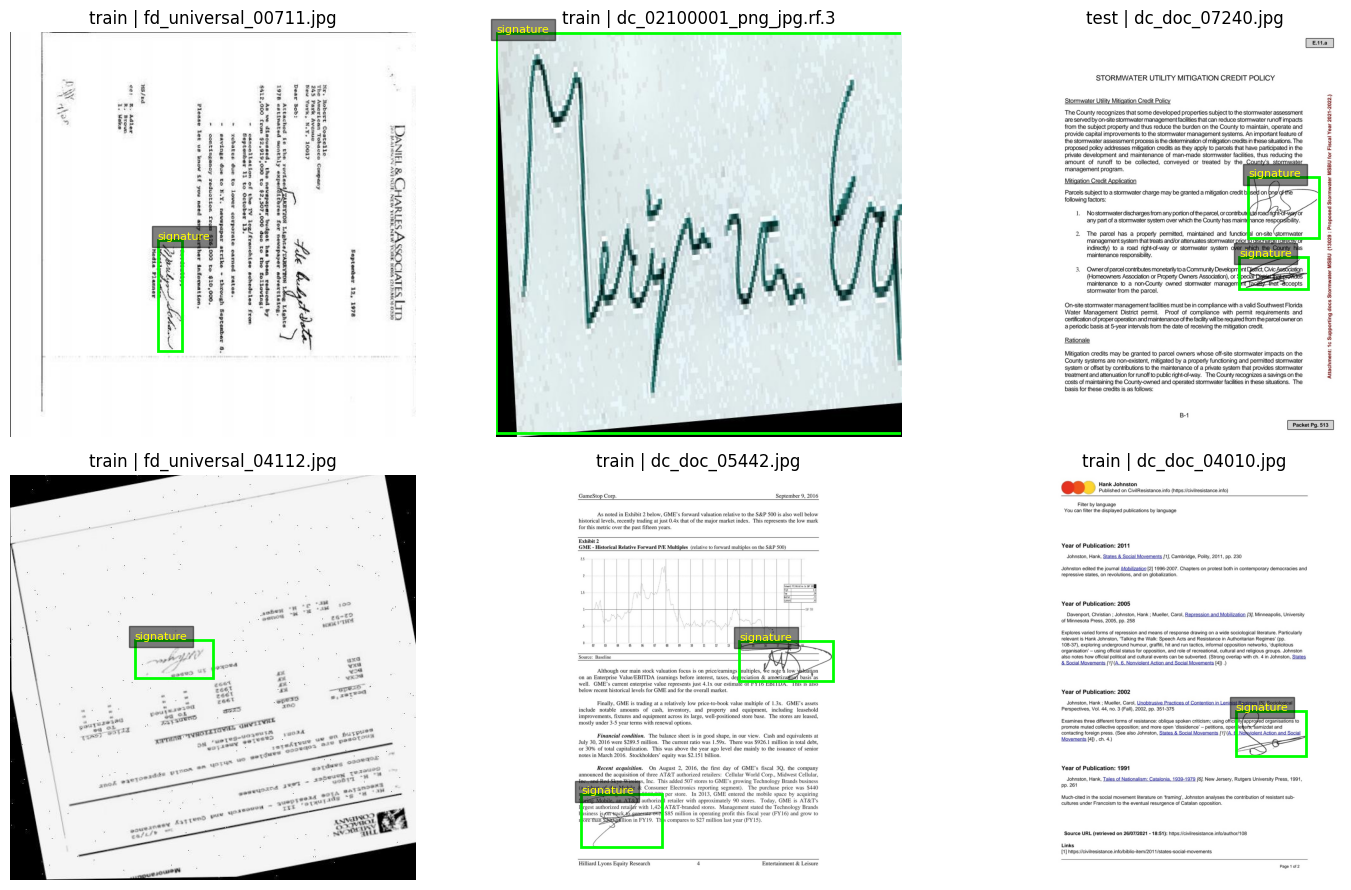

In [29]:
# Visual inspection: sample images with green GT boxes (check annotation correctness).
import matplotlib.pyplot as plt
fig,axs=plt.subplots(2,3,figsize=(15,9)); axs=axs.ravel()
examples = random.Random(SEED).sample(unique_records, min(len(unique_records),6))
for ax in axs: ax.axis('off')
for ax,r in zip(axs,examples):
    with Image.open(r['path']) as im: img=im.convert('RGB')
    ax.imshow(img)
    for a in r['annotations']:
        x,y,w,h = a['bbox']
        ax.add_patch(plt.Rectangle((x,y),w,h,fill=False,edgecolor='lime',linewidth=2))
        ax.text(x,y,a['class_name'],color='yellow',fontsize=8,bbox={'facecolor':'black','alpha':.5})
    ax.set_title(f'{r["final_split"]} | {r["path"].name[:24]}')
plt.tight_layout(); plt.savefig(REPORTS_DIR/'ground_truth_samples.png',dpi=150); plt.show()

## Training: RT-DETRv2-R18 (not Ultralytics)

This is a custom PyTorch training loop so we can explicitly calculate metrics, save a best checkpoint, and log to Comet. **Val metrics decide the best checkpoint; test is evaluated only once after training.**

Settings are conservative for Colab free-tier. Change `EPOCHS` only after the 1-epoch smoke test works. Train size 640 matches the model's intended image size. <https://huggingface.co/docs/transformers/model_doc/rt_detr_v2>

In [30]:
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoImageProcessor, AutoModelForObjectDetection
from torchmetrics.detection.mean_ap import MeanAveragePrecision

assert torch.cuda.is_available(), 'Training RT-DETRv2 realistically requires a GPU. In Colab: Runtime > Change runtime type > T4 GPU.'
device=torch.device('cuda'); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
gpu_name = torch.cuda.get_device_name(0)
gpu_total_gb = torch.cuda.get_device_properties(0).total_memory / 1024**3
print('GPU:', gpu_name, '| VRAM GB:', round(gpu_total_gb, 1), '| Torch:', torch.__version__)
print('Microbatch:', BATCH_SIZE, '| effective batch:', BATCH_SIZE * GRAD_ACCUM)
if 'T4' not in gpu_name.upper():
    print('NOTE: Config tuned for T4, but GPU differs; monitor VRAM and adjust BATCH_SIZE.')
if gpu_total_gb < 14 and BATCH_SIZE > 1:
    print('WARNING: GPU VRAM is lower than expected for T4; consider BATCH_SIZE=1.')

assert IMAGE_SIZE == 640, 'This checkpoint is designed for 640px inputs; keep IMAGE_SIZE=640.'
processor = AutoImageProcessor.from_pretrained(MODEL_ID, use_fast=False)
# Preserve checkpoint processing defaults; model was trained at 640.
print('Processor:',type(processor).__name__)
model = AutoModelForObjectDetection.from_pretrained(
    MODEL_ID, num_labels=len(label_names), id2label=id2label, label2id=label2id,
    ignore_mismatched_sizes=True)
model.to(device)
print('Loaded detector:',type(model).__name__,'| classes:',len(label_names))

GPU: Tesla T4 | VRAM GB: 14.6 | Torch: 2.14.1+cu130
Microbatch: 8 | effective batch: 8
Processor: RTDetrImageProcessor


Some weights of RTDetrV2ForObjectDetection were not initialized from the model checkpoint at PekingU/rtdetr_v2_r18vd and are newly initialized because the shapes did not match:
- model.decoder.class_embed.0.bias: found shape torch.Size([80]) in the checkpoint and torch.Size([1]) in the model instantiated
- model.decoder.class_embed.0.weight: found shape torch.Size([80, 256]) in the checkpoint and torch.Size([1, 256]) in the model instantiated
- model.decoder.class_embed.1.bias: found shape torch.Size([80]) in the checkpoint and torch.Size([1]) in the model instantiated
- model.decoder.class_embed.1.weight: found shape torch.Size([80, 256]) in the checkpoint and torch.Size([1, 256]) in the model instantiated
- model.decoder.class_embed.2.bias: found shape torch.Size([80]) in the checkpoint and torch.Size([1]) in the model instantiated
- model.decoder.class_embed.2.weight: found shape torch.Size([80, 256]) in the checkpoint and torch.Size([1, 256]) in the model instantiated
- model.denoi

Loaded detector: RTDetrV2ForObjectDetection | classes: 1


In [31]:
class CocoCleanDataset(Dataset):
    def __init__(self, split, augment=False):
        folder=CLEAN_DIR/split
        self.data=json.loads((folder/'_annotations.coco.json').read_text())
        self.folder=folder; self.augment=augment
        self.images=self.data['images']; self.annotations=defaultdict(list)
        for a in self.data['annotations']: self.annotations[a['image_id']].append(a)
    def __len__(self): return len(self.images)
    def __getitem__(self,index):
        im=self.images[index]
        path=self.folder/im['file_name']
        with Image.open(path) as f: image=f.convert('RGB')
        # Appearance-only augmentation; geometrical transforms require bbox transforms.
        if self.augment:
            if random.random()<0.35: image=ImageEnhance.Brightness(image).enhance(random.uniform(.88,1.12))
            if random.random()<0.35: image=ImageEnhance.Contrast(image).enhance(random.uniform(.88,1.12))
        anns=[dict(a) for a in self.annotations[im['id']]]
        encoded=processor(images=image, annotations={'image_id':int(im['id']), 'annotations':anns},
                          return_tensors='pt')
        return {'pixel_values':encoded['pixel_values'].squeeze(0),
                'labels':encoded['labels'][0],
                'raw_target':{'boxes':torch.tensor([
                    [a['bbox'][0],a['bbox'][1],a['bbox'][0]+a['bbox'][2],a['bbox'][1]+a['bbox'][3]]
                    for a in anns],dtype=torch.float32).reshape(-1,4),
                    'labels':torch.tensor([a['category_id'] for a in anns],dtype=torch.int64)},
                'original_size':(im['height'],im['width'])}

def collate_fn(batch):
    return {'pixel_values':torch.stack([x['pixel_values'] for x in batch]),
            'labels':[x['labels'] for x in batch],
            'raw_targets':[x['raw_target'] for x in batch],
            'original_sizes':[x['original_size'] for x in batch]}

train_ds=CocoCleanDataset('train',augment=True)
val_ds=CocoCleanDataset('valid',augment=False)
test_ds=CocoCleanDataset('test',augment=False)
train_loader=DataLoader(train_ds,batch_size=BATCH_SIZE,shuffle=True,num_workers=NUM_WORKERS,
                        collate_fn=collate_fn,pin_memory=True)
val_loader=DataLoader(val_ds,batch_size=1,shuffle=False,num_workers=NUM_WORKERS,collate_fn=collate_fn)
test_loader=DataLoader(test_ds,batch_size=1,shuffle=False,num_workers=NUM_WORKERS,collate_fn=collate_fn)
print('Train / valid / test:',len(train_ds),len(val_ds),len(test_ds))
# Run one complete processor smoke-test, including one bbox target.
ex=train_ds[0]
print('Preprocessed input:',tuple(ex['pixel_values'].shape),'| GT boxes:',len(ex['raw_target']['labels']))

Train / valid / test: 22953 3287 2718
Preprocessed input: (3, 640, 640) | GT boxes: 1


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [32]:
# Comet online experiment: metrics, parameters, dataset SHA, and later S3 model URI.
# Colab Secrets > COMET_API_KEY, optionally COMET_WORKSPACE (grant notebook access).
comet_experiment = None
DATASET_SHA256 = sha256_file(zip_path)
if USE_COMET:
    import comet_ml
    comet_experiment = comet_ml.start(
        api_key=secret_or_none('COMET_API_KEY'),
        workspace=secret_or_none('COMET_WORKSPACE') or None,
        project_name=COMET_PROJECT,
        mode='create',
        experiment_config=comet_ml.ExperimentConfig(
            name=RUN_VERSION, tags=['signature-detection', 'rtdetrv2', 'colab']
        )
    )
    comet_experiment.log_parameters({
        'run_version': RUN_VERSION,
        'model': MODEL_ID, 'epochs': EPOCHS, 'batch_size': BATCH_SIZE,
        'grad_accum': GRAD_ACCUM, 'lr': LR, 'image_size': IMAGE_SIZE,
        'dataset_sha256': DATASET_SHA256,
        'classes': ','.join(label_names), 'seed': SEED,
        'hf_repo_id': HF_DATASET_REPO if ZIP_SOURCE=='huggingface' else None,
        'hf_dataset_commit': HF_RESOLVED_COMMIT,
        'early_stopping': EARLY_STOPPING,
        'early_stopping_metric': EARLY_STOPPING_METRIC,
        'early_stopping_patience': EARLY_STOPPING_PATIENCE,
        'early_stopping_min_delta': EARLY_STOPPING_MIN_DELTA,
        'early_stopping_min_epochs': EARLY_STOPPING_MIN_EPOCHS,
        'phash_threshold': PHASH_THRESHOLD, 'ssim_threshold': SSIM_THRESHOLD
    })
    print('Comet ONLINE tracking enabled | project:', COMET_PROJECT, '| run:', RUN_VERSION)
else:
    print('Comet disabled: graphs and CSV will still be saved locally.')


COMET WARNING: To get all data logged automatically, import comet_ml before the following modules: torch, keras, tensorflow, sklearn.
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     name                  : v20261109T142002Z-8a4d7444
COMET INFO:     url                   : https://www.comet.com/abdullah-khalid/signature-ai-detection/a17a15a18e2440209ea30f69070af9d5
COMET INFO:   Metrics:
COMET INFO:     epoch_seconds         : 2889.3
COMET INFO:     gpu_peak_allocated_gb : 3.02
COMET INFO:     learning_rate         : 2e-05
COMET INFO:     train_loss            : 9.023869797915877
COMET INFO:     val_loss              : 4.807204135038256
COMET INFO:     val_map               : 0.6231895089149475
COMET INFO:     val_map50  

Comet ONLINE tracking enabled | project: signature-ai-detection | run: v20261109T142002Z-8a4d7444


In [33]:
from tqdm.auto import tqdm

# T4-friendly RT-DETRv2 training: fp16 mixed precision + gradient accumulation.
# Select best checkpoint by validation mAP@50; early-stop on stagnant validation mAP.
# The held-out TEST set is never used to select a checkpoint or decide when to stop.
# FIX 1: guard against stale DataLoaders (config changed after cell 15 was run).
# FIX 2: every new best checkpoint + training history is backed up to S3 immediately,
#        so a Colab disconnect does not lose the trained model.

# ---- FIX 1: config / DataLoader consistency check ----
assert train_loader.batch_size == BATCH_SIZE, (
    f'train_loader batch_size={train_loader.batch_size} but BATCH_SIZE={BATCH_SIZE}. '
    'Re-run cells 2 -> 14 -> 15 -> 16 in order, then this cell.')
print(f'Batches/epoch: {len(train_loader)} | microbatch: {BATCH_SIZE} | accum: {GRAD_ACCUM} '
      f'| effective batch: {BATCH_SIZE * GRAD_ACCUM} | workers: {train_loader.num_workers}')

# ---- FIX 2: S3 checkpoint backup (separate from the immutable versions/ registry) ----
_s3_ckpt = None
if UPLOAD_TO_S3:
    import boto3
    from botocore.config import Config
    _s3_kwargs = {
        'aws_access_key_id': secret_or_none('AWS_ACCESS_KEY_ID'),
        'aws_secret_access_key': secret_or_none('AWS_SECRET_ACCESS_KEY'),
        'region_name': secret_or_none('AWS_REGION'),
    }
    if secret_or_none('AWS_SESSION_TOKEN'):
        _s3_kwargs['aws_session_token'] = secret_or_none('AWS_SESSION_TOKEN')
    _s3_ckpt = boto3.Session(**_s3_kwargs).client(
        's3', config=Config(retries={'mode': 'standard', 'max_attempts': 5}))
    _CKPT_BUCKET = secret_or_none('AWS_S3_BUCKET')
    _CKPT_PREFIX = f"{S3_PREFIX.strip('/')}/checkpoints/{RUN_VERSION}"
    print('S3 checkpoint backups ->', f's3://{_CKPT_BUCKET}/{_CKPT_PREFIX}/')

def backup_to_s3(include_model):
    """Never crash training because of a backup problem; just warn."""
    if _s3_ckpt is None:
        return
    try:
        _s3_ckpt.upload_file(str(REPORTS_DIR / 'training_history.csv'), _CKPT_BUCKET,
                             f'{_CKPT_PREFIX}/training_history.csv')
        if include_model:
            for p in sorted(MODEL_DIR.rglob('*')):
                if p.is_file():
                    _s3_ckpt.upload_file(str(p), _CKPT_BUCKET,
                                         f'{_CKPT_PREFIX}/best_model/{p.relative_to(MODEL_DIR).as_posix()}')
            tqdm.write(f'S3 backup OK: s3://{_CKPT_BUCKET}/{_CKPT_PREFIX}/best_model/')
    except Exception as e:
        tqdm.write(f'WARNING: S3 backup failed ({e!r}); training continues, model still on local disk.')

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
use_amp = (device.type == 'cuda')
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

def run_validation(loader, with_loss=True):
    model.eval()
    evaluator = MeanAveragePrecision(box_format='xyxy', iou_type='bbox')
    losses = []
    val_bar = tqdm(loader, total=len(loader), desc='Validation', unit='batch',
                   leave=False, dynamic_ncols=True)
    with torch.inference_mode():
        for batch in val_bar:
            px = batch['pixel_values'].to(device, non_blocking=True)
            labels = [{k: v.to(device) if torch.is_tensor(v) else v for k, v in x.items()}
                      for x in batch['labels']]
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
                outputs = model(pixel_values=px, labels=labels if with_loss else None)
            if with_loss and outputs.loss is not None:
                losses.append(float(outputs.loss.detach().float()))
            sizes = torch.tensor(batch['original_sizes'], dtype=torch.long, device=device)
            predictions = processor.post_process_object_detection(
                outputs, threshold=SCORE_THRESHOLD, target_sizes=sizes)
            pred_cpu = [{'boxes': p['boxes'].detach().float().cpu(),
                         'scores': p['scores'].detach().float().cpu(),
                         'labels': p['labels'].detach().cpu()} for p in predictions]
            target_cpu = [{'boxes': t['boxes'].cpu(), 'labels': t['labels'].cpu()}
                          for t in batch['raw_targets']]
            evaluator.update(pred_cpu, target_cpu)
    val_bar.close()
    metrics = evaluator.compute()
    result = {k: float(v) for k, v in metrics.items()
              if isinstance(v, torch.Tensor) and v.ndim == 0}
    result['loss'] = float(np.mean(losses)) if losses else float('nan')
    return result

history = []
best_map50 = -1.0
best_monitored_value = float('-inf')
best_epoch = 0
bad_epochs = 0
stopped_early = False
stop_reason = 'max_epochs_reached'

epoch_bar = tqdm(range(1, EPOCHS + 1), total=EPOCHS, desc='Overall Training',
                 unit='epoch', dynamic_ncols=True)

for epoch in epoch_bar:
    model.train()
    optimizer.zero_grad(set_to_none=True)
    torch.cuda.reset_peak_memory_stats(device)
    epoch_start = time.time()
    losses = []

    train_bar = tqdm(train_loader, total=len(train_loader),
                     desc=f'Epoch {epoch}/{EPOCHS} Training', unit='batch',
                     leave=False, dynamic_ncols=True)

    for step, batch in enumerate(train_bar, 1):
        px = batch['pixel_values'].to(device, non_blocking=True)
        targets = [{k: v.to(device) if torch.is_tensor(v) else v for k, v in x.items()}
                   for x in batch['labels']]
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
            outputs = model(pixel_values=px, labels=targets)
            loss = outputs.loss
        if not torch.isfinite(loss):
            raise RuntimeError(f'Non-finite loss at epoch={epoch}, batch={step}. Review labels and LR.')
        losses.append(float(loss.detach().float()))
        # Scale the final incomplete accumulation window correctly.
        window_start = ((step - 1) // GRAD_ACCUM) * GRAD_ACCUM
        window_size = min(GRAD_ACCUM, len(train_loader) - window_start)
        scaler.scale(loss / window_size).backward()
        if step % GRAD_ACCUM == 0 or step == len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
        train_bar.set_postfix(loss=f'{loss.item():.4f}')
    train_bar.close()

    val = run_validation(val_loader, with_loss=True)
    row = {
        'epoch': epoch,
        'train_loss': float(np.mean(losses)),
        'val_loss': val['loss'],
        'val_map': val.get('map', float('nan')),
        'val_map50': val.get('map_50', float('nan')),
        'val_map75': val.get('map_75', float('nan')),
        'val_mar100': val.get('mar_100', float('nan')),
        'epoch_seconds': round(time.time() - epoch_start, 1),
        'learning_rate': float(optimizer.param_groups[0]['lr']),
        'gpu_peak_allocated_gb': round(torch.cuda.max_memory_allocated(device) / 1024**3, 2),
    }
    history.append(row)
    pd.DataFrame(history).to_csv(REPORTS_DIR / 'training_history.csv', index=False)
    tqdm.write(f'Epoch {epoch} metrics: {row}')
    if comet_experiment:
        comet_experiment.log_metrics({k: v for k, v in row.items() if k != 'epoch'},
                                     step=epoch, epoch=epoch)
    epoch_bar.set_postfix({'train_loss': f"{row['train_loss']:.4f}",
                           'val_loss': f"{row['val_loss']:.4f}",
                           'mAP50': f"{row['val_map50']:.4f}"})

    monitored = row[EARLY_STOPPING_METRIC]
    if not math.isfinite(monitored):
        raise RuntimeError(f'Validation metric {EARLY_STOPPING_METRIC} is non-finite; inspect labels.')
    improved = (monitored > best_monitored_value + EARLY_STOPPING_MIN_DELTA)
    if improved:
        best_monitored_value = monitored
        best_map50 = row['val_map50']
        best_epoch = epoch
        bad_epochs = 0
        model.save_pretrained(MODEL_DIR, safe_serialization=True)
        processor.save_pretrained(MODEL_DIR)
        save_json(MODEL_DIR / 'label_names.json', label_names)
        save_json(MODEL_DIR / 'model_metadata.json', {
            'base_model': MODEL_ID, 'run_version': RUN_VERSION, 'best_epoch': best_epoch,
            'best_val_map50': best_map50, 'best_monitored_value': best_monitored_value,
            'early_stopping_metric': EARLY_STOPPING_METRIC, 'labels': label_names,
            'batch_size': BATCH_SIZE, 'grad_accum': GRAD_ACCUM, 'lr': LR})
        tqdm.write(f'Saved best checkpoint: {MODEL_DIR} | epoch: {best_epoch} | mAP@50: {best_map50:.4f}')
        backup_to_s3(include_model=True)
    else:
        bad_epochs += 1
        tqdm.write(f'No meaningful validation improvement: {bad_epochs}/{EARLY_STOPPING_PATIENCE}')
        backup_to_s3(include_model=False)

    if EARLY_STOPPING and epoch >= EARLY_STOPPING_MIN_EPOCHS and bad_epochs >= EARLY_STOPPING_PATIENCE:
        stopped_early = True
        stop_reason = f'{EARLY_STOPPING_METRIC} did not improve > {EARLY_STOPPING_MIN_DELTA} for {bad_epochs} epochs'
        tqdm.write(f'EARLY STOPPING: {stop_reason} | best epoch: {best_epoch}')
        break

epoch_bar.close()

assert (MODEL_DIR / 'config.json').exists(), 'No best checkpoint created; check training and validation.'
completed_epochs = len(history)
early_stopping_summary = {
    'enabled': EARLY_STOPPING,
    'monitor': EARLY_STOPPING_METRIC,
    'mode': 'max',
    'patience': EARLY_STOPPING_PATIENCE,
    'min_delta': EARLY_STOPPING_MIN_DELTA,
    'minimum_epochs': EARLY_STOPPING_MIN_EPOCHS,
    'configured_max_epochs': EPOCHS,
    'epochs_completed': completed_epochs,
    'best_epoch': best_epoch,
    'best_val_map50': best_map50,
    'best_monitored_value': best_monitored_value,
    'stopped_early': stopped_early,
    'stop_reason': stop_reason,
}
save_json(REPORTS_DIR / 'early_stopping_summary.json', early_stopping_summary)
if comet_experiment:
    comet_experiment.log_metrics({
        'best_val_map50': best_map50,
        'best_epoch': best_epoch,
        'epochs_completed': completed_epochs,
        'stopped_early': int(stopped_early),
    })
print('Training complete | epochs:', completed_epochs, '| best epoch:', best_epoch,
      '| best val mAP@50:', round(best_map50, 4))

Batches/epoch: 2870 | microbatch: 8 | accum: 1 | effective batch: 8 | workers: 4
S3 checkpoint backups -> s3://signatureai-df-detr-models/signatureai/detection/checkpoints/v20261109T142002Z-8a4d7444/


Overall Training:   0%|          | 0/5 [00:00<?, ?epoch/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch 1/5 Training:   0%|          | 0/2870 [00:00<?, ?batch/s]

Validation:   0%|          | 0/3287 [00:00<?, ?batch/s]

Epoch 1 metrics: {'epoch': 1, 'train_loss': 14.907977404411662, 'val_loss': 4.876633426754225, 'val_map': 0.5950353145599365, 'val_map50': 0.8393340706825256, 'val_map75': 0.6190090775489807, 'val_mar100': 0.7357601523399353, 'epoch_seconds': 1824.9, 'learning_rate': 2e-05, 'gpu_peak_allocated_gb': 3.96}
Saved best checkpoint: /content/signature_ai_work/run/best_model | epoch: 1 | mAP@50: 0.8393


... (2 outputs left out)

Epoch 2 metrics: {'epoch': 2, 'train_loss': 7.663859131444207, 'val_loss': 4.841829600983084, 'val_map': 0.5985816121101379, 'val_map50': 0.8336071968078613, 'val_map75': 0.6234650015830994, 'val_mar100': 0.7387794256210327, 'epoch_seconds': 1885.8, 'learning_rate': 2e-05, 'gpu_peak_allocated_gb': 3.96}
No meaningful validation improvement: 1/2


Epoch 3/5 Training:   0%|          | 0/2870 [00:00<?, ?batch/s]

Validation:   0%|          | 0/3287 [00:00<?, ?batch/s]

Epoch 3 metrics: {'epoch': 3, 'train_loss': 7.255096518619551, 'val_loss': 4.819452449951943, 'val_map': 0.5984500050544739, 'val_map50': 0.8265854120254517, 'val_map75': 0.6225131154060364, 'val_mar100': 0.7282441258430481, 'epoch_seconds': 1960.0, 'learning_rate': 2e-05, 'gpu_peak_allocated_gb': 3.96}
No meaningful validation improvement: 2/2
EARLY STOPPING: val_map50 did not improve > 0.001 for 2 epochs | best epoch: 1
Training complete | epochs: 3 | best epoch: 1 | best val mAP@50: 0.8393


In [34]:

# # ============================================================
# # RT-DETRv2 TRAINING WITH LIVE PROGRESS BARS
# # T4 GPU | FP16 | Gradient Accumulation | Early Stopping
# # Best Checkpoint | Comet Tracking | Validation mAP
# # ============================================================

# from tqdm.auto import tqdm
# import time
# import math
# import numpy as np
# import pandas as pd
# import torch

# # ------------------------------------------------------------
# # 1. OPTIMIZER & MIXED PRECISION
# # ------------------------------------------------------------

# optimizer = torch.optim.AdamW(
#     model.parameters(),
#     lr=LR,
#     weight_decay=1e-4
# )

# use_amp = (device.type == 'cuda')

# scaler = torch.amp.GradScaler(
#     'cuda',
#     enabled=use_amp
# )


# # ------------------------------------------------------------
# # 2. VALIDATION WITH LIVE PROGRESS BAR
# # ------------------------------------------------------------

# def run_validation(loader, with_loss=True):

#     model.eval()

#     evaluator = MeanAveragePrecision(
#         box_format='xyxy',
#         iou_type='bbox'
#     )

#     losses = []

#     val_bar = tqdm(
#         loader,
#         total=len(loader),
#         desc="Validation",
#         unit="batch",
#         leave=False,
#         dynamic_ncols=True,
#         position=1
#     )

#     with torch.inference_mode():

#         for step, batch in enumerate(val_bar, 1):

#             px = batch['pixel_values'].to(
#                 device,
#                 non_blocking=True
#             )

#             labels = [
#                 {
#                     k: v.to(device)
#                     if torch.is_tensor(v) else v
#                     for k, v in x.items()
#                 }
#                 for x in batch['labels']
#             ]

#             with torch.autocast(
#                 device_type='cuda',
#                 dtype=torch.float16,
#                 enabled=use_amp
#             ):

#                 outputs = model(
#                     pixel_values=px,
#                     labels=labels if with_loss else None
#                 )

#             if with_loss and outputs.loss is not None:

#                 val_loss = float(
#                     outputs.loss.detach().float()
#                 )

#                 losses.append(val_loss)

#                 val_bar.set_postfix({
#                     "val_loss": f"{val_loss:.4f}",
#                     "avg_loss": f"{np.mean(losses):.4f}"
#                 })

#             sizes = torch.tensor(
#                 batch['original_sizes'],
#                 dtype=torch.long,
#                 device=device
#             )

#             predictions = processor.post_process_object_detection(
#                 outputs,
#                 threshold=SCORE_THRESHOLD,
#                 target_sizes=sizes
#             )

#             pred_cpu = [
#                 {
#                     'boxes': p['boxes'].detach().float().cpu(),
#                     'scores': p['scores'].detach().float().cpu(),
#                     'labels': p['labels'].detach().cpu()
#                 }
#                 for p in predictions
#             ]

#             target_cpu = [
#                 {
#                     'boxes': t['boxes'].cpu(),
#                     'labels': t['labels'].cpu()
#                 }
#                 for t in batch['raw_targets']
#             ]

#             evaluator.update(
#                 pred_cpu,
#                 target_cpu
#             )

#     val_bar.close()

#     metrics = evaluator.compute()

#     result = {
#         k: float(v)
#         for k, v in metrics.items()
#         if isinstance(v, torch.Tensor) and v.ndim == 0
#     }

#     result['loss'] = (
#         float(np.mean(losses))
#         if losses else float('nan')
#     )

#     return result


# # ------------------------------------------------------------
# # 3. TRAINING CONFIGURATION
# # ------------------------------------------------------------

# history = []

# best_map50 = -1.0
# best_monitored_value = float('-inf')
# best_epoch = 0

# bad_epochs = 0
# stopped_early = False
# stop_reason = 'max_epochs_reached'

# print("=" * 60)
# print("STARTING RT-DETRv2 TRAINING")
# print("=" * 60)

# print(f"Device                : {device}")
# print(f"Maximum Epochs        : {EPOCHS}")
# print(f"Training Batches      : {len(train_loader)}")
# print(f"Validation Batches    : {len(val_loader)}")
# print(f"Gradient Accumulation : {GRAD_ACCUM}")
# print(f"Learning Rate         : {LR}")
# print(f"Mixed Precision       : {use_amp}")
# print(f"Early Stopping        : {EARLY_STOPPING}")
# print(f"Early Stop Patience   : {EARLY_STOPPING_PATIENCE}")

# print("=" * 60)


# # ------------------------------------------------------------
# # 4. EPOCH PROGRESS BAR
# # ------------------------------------------------------------

# epoch_bar = tqdm(
#     range(1, EPOCHS + 1),
#     total=EPOCHS,
#     desc="Overall Training",
#     unit="epoch",
#     position=0,
#     dynamic_ncols=True
# )


# for epoch in epoch_bar:

#     model.train()

#     optimizer.zero_grad(set_to_none=True)

#     if device.type == 'cuda':
#         torch.cuda.reset_peak_memory_stats(device)

#     epoch_start = time.time()

#     losses = []
#     running_loss = 0.0

#     # --------------------------------------------------------
#     # 5. BATCH PROGRESS BAR
#     # --------------------------------------------------------

#     train_bar = tqdm(
#         train_loader,
#         total=len(train_loader),
#         desc=f"Epoch {epoch}/{EPOCHS} Training",
#         unit="batch",
#         position=1,
#         leave=False,
#         dynamic_ncols=True
#     )

#     for step, batch in enumerate(train_bar, 1):

#         px = batch['pixel_values'].to(
#             device,
#             non_blocking=True
#         )

#         targets = [
#             {
#                 k: v.to(device)
#                 if torch.is_tensor(v) else v
#                 for k, v in x.items()
#             }
#             for x in batch['labels']
#         ]

#         # ----------------------------------------------------
#         # FORWARD PASS
#         # ----------------------------------------------------

#         with torch.autocast(
#             device_type='cuda',
#             dtype=torch.float16,
#             enabled=use_amp
#         ):

#             outputs = model(
#                 pixel_values=px,
#                 labels=targets
#             )

#             loss = outputs.loss

#         if not torch.isfinite(loss):

#             raise RuntimeError(
#                 f"Non-finite loss detected at "
#                 f"epoch={epoch}, batch={step}"
#             )

#         current_loss = float(
#             loss.detach().float()
#         )

#         losses.append(current_loss)

#         running_loss += current_loss

#         average_loss = running_loss / step

#         # ----------------------------------------------------
#         # GRADIENT ACCUMULATION
#         # ----------------------------------------------------

#         window_start = (
#             ((step - 1) // GRAD_ACCUM) * GRAD_ACCUM
#         )

#         window_size = min(
#             GRAD_ACCUM,
#             len(train_loader) - window_start
#         )

#         scaler.scale(
#             loss / window_size
#         ).backward()

#         if (
#             step % GRAD_ACCUM == 0
#             or step == len(train_loader)
#         ):

#             scaler.unscale_(optimizer)

#             torch.nn.utils.clip_grad_norm_(
#                 model.parameters(),
#                 max_norm=1.0
#             )

#             scaler.step(optimizer)
#             scaler.update()

#             optimizer.zero_grad(set_to_none=True)

#         # ----------------------------------------------------
#         # LIVE LOSS + GPU MEMORY
#         # ----------------------------------------------------

#         if device.type == 'cuda':

#             gpu_memory = (
#                 torch.cuda.memory_allocated(device)
#                 / 1024**3
#             )

#         else:
#             gpu_memory = 0.0

#         train_bar.set_postfix({
#             "loss": f"{current_loss:.4f}",
#             "avg_loss": f"{average_loss:.4f}",
#             "GPU_GB": f"{gpu_memory:.2f}"
#         })

#     train_bar.close()

#     # --------------------------------------------------------
#     # 6. VALIDATION AFTER EACH EPOCH
#     # --------------------------------------------------------

#     tqdm.write(
#         f"\nEpoch {epoch}/{EPOCHS} completed."
#         f" Running validation..."
#     )

#     val = run_validation(
#         val_loader,
#         with_loss=True
#     )

#     epoch_duration = time.time() - epoch_start

#     if device.type == 'cuda':

#         peak_gpu = (
#             torch.cuda.max_memory_allocated(device)
#             / 1024**3
#         )

#     else:
#         peak_gpu = 0.0

#     # --------------------------------------------------------
#     # 7. SAVE METRICS
#     # --------------------------------------------------------

#     row = {
#         'epoch': epoch,
#         'train_loss': float(np.mean(losses)),
#         'val_loss': val['loss'],
#         'val_map': val.get('map', float('nan')),
#         'val_map50': val.get('map_50', float('nan')),
#         'val_map75': val.get('map_75', float('nan')),
#         'val_mar100': val.get('mar_100', float('nan')),
#         'epoch_seconds': round(epoch_duration, 1),
#         'learning_rate': float(
#             optimizer.param_groups[0]['lr']
#         ),
#         'gpu_peak_allocated_gb': round(peak_gpu, 2)
#     }

#     history.append(row)

#     pd.DataFrame(history).to_csv(
#         REPORTS_DIR / 'training_history.csv',
#         index=False
#     )

#     # --------------------------------------------------------
#     # 8. COMET TRACKING
#     # --------------------------------------------------------

#     if comet_experiment:

#         comet_experiment.log_metrics(
#             {
#                 k: v
#                 for k, v in row.items()
#                 if k != 'epoch'
#             },
#             step=epoch,
#             epoch=epoch
#         )

#     # --------------------------------------------------------
#     # 9. EARLY STOPPING & BEST CHECKPOINT
#     # --------------------------------------------------------

#     monitored = row[EARLY_STOPPING_METRIC]

#     if not math.isfinite(monitored):

#         raise RuntimeError(
#             f"Validation metric "
#             f"{EARLY_STOPPING_METRIC} is non-finite."
#         )

#     improved = (
#         monitored
#         > best_monitored_value + EARLY_STOPPING_MIN_DELTA
#     )

#     if improved:

#         best_monitored_value = monitored
#         best_map50 = row['val_map50']
#         best_epoch = epoch
#         bad_epochs = 0

#         model.save_pretrained(
#             MODEL_DIR,
#             safe_serialization=True
#         )

#         processor.save_pretrained(MODEL_DIR)

#         save_json(
#             MODEL_DIR / 'label_names.json',
#             label_names
#         )

#         save_json(
#             MODEL_DIR / 'model_metadata.json',
#             {
#                 'base_model': MODEL_ID,
#                 'best_epoch': best_epoch,
#                 'best_val_map50': best_map50,
#                 'best_monitored_value': best_monitored_value,
#                 'early_stopping_metric': EARLY_STOPPING_METRIC,
#                 'labels': label_names
#             }
#         )

#         tqdm.write(
#             f"BEST MODEL SAVED | "
#             f"Epoch {best_epoch} | "
#             f"mAP@50: {best_map50:.4f}"
#         )

#     else:

#         bad_epochs += 1

#         tqdm.write(
#             f"No improvement: "
#             f"{bad_epochs}/{EARLY_STOPPING_PATIENCE}"
#         )

#     # --------------------------------------------------------
#     # 10. EPOCH SUMMARY
#     # --------------------------------------------------------

#     tqdm.write(
#         f"\n{'=' * 55}\n"
#         f"EPOCH {epoch}/{EPOCHS} SUMMARY\n"
#         f"{'=' * 55}\n"
#         f"Training Loss : {row['train_loss']:.4f}\n"
#         f"Validation Loss: {row['val_loss']:.4f}\n"
#         f"Validation mAP: {row['val_map']:.4f}\n"
#         f"Validation mAP@50: {row['val_map50']:.4f}\n"
#         f"Best mAP@50   : {best_map50:.4f}\n"
#         f"Epoch Time    : {epoch_duration / 60:.2f} min\n"
#         f"Peak GPU      : {peak_gpu:.2f} GB\n"
#         f"{'=' * 55}\n"
#     )

#     # Update overall epoch progress bar
#     epoch_bar.set_postfix({
#         "train_loss": f"{row['train_loss']:.4f}",
#         "val_loss": f"{row['val_loss']:.4f}",
#         "mAP50": f"{row['val_map50']:.4f}",
#         "best": f"{best_map50:.4f}"
#     })

#     # --------------------------------------------------------
#     # 11. EARLY STOPPING CONDITION
#     # --------------------------------------------------------

#     if (
#         EARLY_STOPPING
#         and epoch >= EARLY_STOPPING_MIN_EPOCHS
#         and bad_epochs >= EARLY_STOPPING_PATIENCE
#     ):

#         stopped_early = True

#         stop_reason = (
#             f"{EARLY_STOPPING_METRIC} did not improve "
#             f"> {EARLY_STOPPING_MIN_DELTA} "
#             f"for {bad_epochs} epochs"
#         )

#         tqdm.write(
#             f"\nEARLY STOPPING TRIGGERED!\n"
#             f"Best Epoch: {best_epoch}\n"
#             f"Best mAP@50: {best_map50:.4f}\n"
#             f"Reason: {stop_reason}"
#         )

#         break


# epoch_bar.close()


# # ------------------------------------------------------------
# # 12. FINAL TRAINING SUMMARY
# # ------------------------------------------------------------

# assert (
#     MODEL_DIR / 'config.json'
# ).exists(), (
#     'No best checkpoint created.'
# )

# completed_epochs = len(history)

# early_stopping_summary = {
#     'enabled': EARLY_STOPPING,
#     'monitor': EARLY_STOPPING_METRIC,
#     'mode': 'max',
#     'patience': EARLY_STOPPING_PATIENCE,
#     'min_delta': EARLY_STOPPING_MIN_DELTA,
#     'minimum_epochs': EARLY_STOPPING_MIN_EPOCHS,
#     'configured_max_epochs': EPOCHS,
#     'epochs_completed': completed_epochs,
#     'best_epoch': best_epoch,
#     'best_val_map50': best_map50,
#     'best_monitored_value': best_monitored_value,
#     'stopped_early': stopped_early,
#     'stop_reason': stop_reason
# }

# save_json(
#     REPORTS_DIR / 'early_stopping_summary.json',
#     early_stopping_summary
# )

# if comet_experiment:

#     comet_experiment.log_metrics({
#         'best_val_map50': best_map50,
#         'best_epoch': best_epoch,
#         'epochs_completed': completed_epochs,
#         'stopped_early': int(stopped_early)
#     })

# print("\n" + "=" * 60)
# print("TRAINING FINISHED")
# print("=" * 60)

# print(f"Completed Epochs : {completed_epochs}")
# print(f"Best Epoch       : {best_epoch}")
# print(f"Best mAP@50      : {best_map50:.4f}")
# print(f"Early Stopped    : {stopped_early}")
# print(f"Best Model Path  : {MODEL_DIR}")

# print("=" * 60)


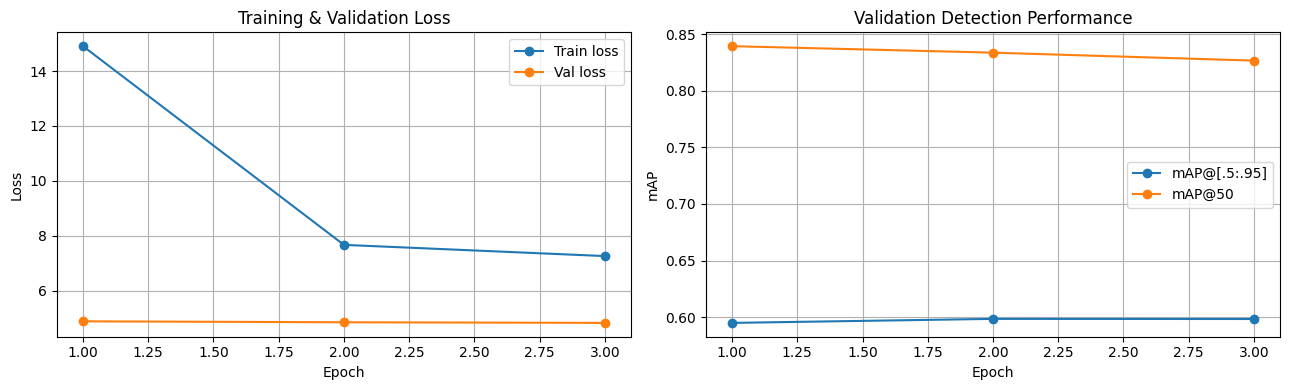

Validation:   0%|          | 0/2718 [00:00<?, ?batch/s]

Held-out test COCO metrics: {'map': 0.5535488724708557, 'map_50': 0.8072282075881958, 'map_75': 0.5733407139778137, 'map_small': 0.037184830754995346, 'map_medium': 0.3841439187526703, 'map_large': 0.6489198207855225, 'mar_1': 0.5014976859092712, 'mar_10': 0.7129320502281189, 'mar_100': 0.7152073979377747, 'mar_small': 0.29230770468711853, 'mar_medium': 0.6289317607879639, 'mar_large': 0.7758817672729492, 'map_per_class': -1.0, 'mar_100_per_class': -1.0, 'classes': 0.0, 'loss': 5.037896920541045}


In [35]:
# Plot training/evaluation graphs and evaluate held-out TEST ONCE after model selection.
hist=pd.DataFrame(history)
fig,axes=plt.subplots(1,2,figsize=(13,4))
axes[0].plot(hist['epoch'],hist['train_loss'],marker='o',label='Train loss')
axes[0].plot(hist['epoch'],hist['val_loss'],marker='o',label='Val loss')
axes[0].set(xlabel='Epoch',ylabel='Loss',title='Training & Validation Loss'); axes[0].grid(True);axes[0].legend()
axes[1].plot(hist['epoch'],hist['val_map'],marker='o',label='mAP@[.5:.95]')
axes[1].plot(hist['epoch'],hist['val_map50'],marker='o',label='mAP@50')
axes[1].set(xlabel='Epoch',ylabel='mAP',title='Validation Detection Performance'); axes[1].grid(True);axes[1].legend()
plt.tight_layout();plt.savefig(REPORTS_DIR/'training_curves.png',dpi=180);plt.show()

# Load best val checkpoint before the one-time test.
del model
if torch.cuda.is_available(): torch.cuda.empty_cache()
model=AutoModelForObjectDetection.from_pretrained(MODEL_DIR).to(device)
test_metrics=run_validation(test_loader)
print('Held-out test COCO metrics:',test_metrics)
save_json(REPORTS_DIR/'test_metrics.json',test_metrics)
if comet_experiment:
    comet_experiment.log_metrics({'test_'+k:v for k,v in test_metrics.items()})
    comet_experiment.log_image(str(REPORTS_DIR/'training_curves.png'),name='train_val_curves')
    comet_experiment.log_asset(str(REPORTS_DIR/'dataset_summary.json'))
    comet_experiment.log_asset(str(REPORTS_DIR/'test_metrics.json'))
    comet_experiment.log_asset(str(REPORTS_DIR/'early_stopping_summary.json'))
    # Keep Comet open: S3 model URI is logged after upload in a later cell.

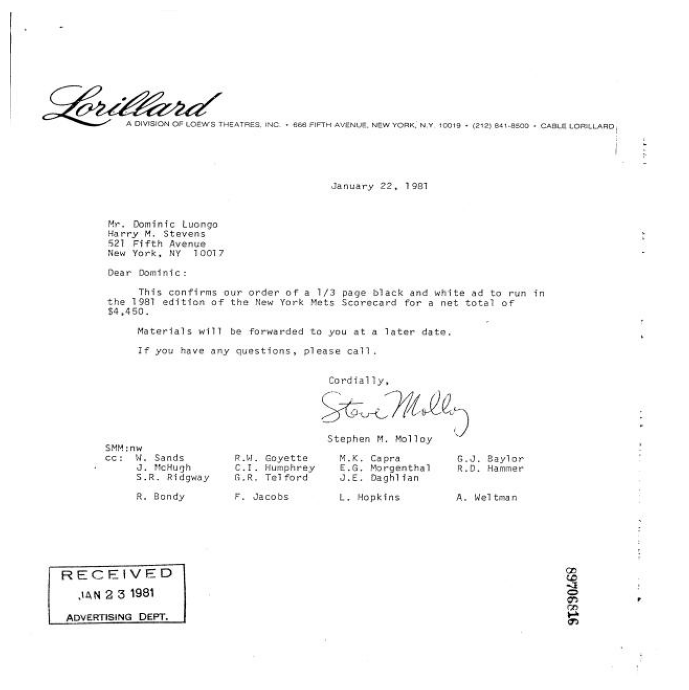

In [36]:
# Inference sample from held-out test: draw predicted signature boxes.
model.eval()
random_test=random.choice(test_ds.images)
with Image.open(test_ds.folder/random_test['file_name']) as f: test_image=f.convert('RGB')
with torch.no_grad():
    inputs=processor(images=test_image,return_tensors='pt').to(device)
    with torch.autocast(device_type='cuda',dtype=torch.float16,enabled=use_amp):
        outputs=model(**inputs)
pred=processor.post_process_object_detection(outputs,
    target_sizes=torch.tensor([[test_image.height,test_image.width]],device=device),threshold=0.35)[0]
fig,ax=plt.subplots(figsize=(10,7));ax.imshow(test_image);ax.axis('off')
for score,label,box in zip(pred['scores'].cpu(),pred['labels'].cpu(),pred['boxes'].cpu()):
    x1,y1,x2,y2=box.tolist()
    ax.add_patch(plt.Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor='red',linewidth=2))
    ax.text(x1,y1,f'{id2label[int(label)]} {float(score):.2f}',color='white',fontsize=9,bbox=dict(facecolor='red',alpha=.7))
plt.tight_layout();plt.savefig(REPORTS_DIR/'prediction_sample.png',dpi=170);plt.show()

## Model registry: immutable S3 versions, checksums and aliases

A complete inference artifact contains model weights, model config, image processor, class mapping and evaluation metadata. Each run is stored at:

` s3://<bucket>/signatureai/detection/versions/<RUN_VERSION>/artifact.zip `

alongside `manifest.json`. The alias `aliases/latest.json` identifies the **latest successfully uploaded** training run. **It is NOT the production model.** `aliases/production.json` is updated only by the optional manual promotion cell after reviewing evaluation results.

For extra protection, enable S3 **Bucket Versioning** in the AWS console, but note that **stored previous object versions incur storage costs**. The independent per-run prefixes in this notebook work even if bucket versioning is disabled. Keep the bucket **private**, with **Block Public Access ON**.


In [42]:
# Package a complete, versioned, inference-ready Hugging Face checkpoint and audit report.
# No model files are committed to GitHub. Save the dataset fingerprint for reproducibility.
import transformers

assert (MODEL_DIR / 'config.json').exists(), 'Missing best model. Run training cells successfully first.'
assert any((MODEL_DIR / n).exists() for n in ['model.safetensors', 'pytorch_model.bin']), 'Missing model weights.'
assert (MODEL_DIR / 'preprocessor_config.json').exists(), 'Missing image processor configuration.'

run_metadata = {
    'schema_version': 1, 'task': 'signature_object_detection',
    'model_name': 'RT-DETRv2-R18', 'base_checkpoint': MODEL_ID,
    'version': RUN_VERSION, 'created_at_utc': datetime.datetime.now(datetime.timezone.utc).isoformat(),
    'dataset_archive_sha256': DATASET_SHA256,
    'huggingface_dataset_repo': HF_DATASET_REPO if ZIP_SOURCE=='huggingface' else None,
    'huggingface_dataset_commit': HF_RESOLVED_COMMIT,
    'labels': list(label_names), 'best_val_map50': float(best_map50),
    'test_metrics': test_metrics,
    'training': {
        'max_epochs': EPOCHS, 'actual_epochs': completed_epochs,
        'best_epoch': best_epoch, 'batch_size': BATCH_SIZE,
        'gradient_accumulation': GRAD_ACCUM, 'effective_batch_size': BATCH_SIZE*GRAD_ACCUM,
        'early_stopping': early_stopping_summary,
        'learning_rate': LR, 'input_size': IMAGE_SIZE, 'seed': SEED,
        'phash_threshold': PHASH_THRESHOLD, 'ssim_threshold': SSIM_THRESHOLD,
    },
    'libraries': {'torch': torch.__version__, 'transformers': transformers.__version__},
    'comet_project': COMET_PROJECT if USE_COMET else None,
    'comet_experiment_key': comet_experiment.get_key() if comet_experiment else None,
    'notes': 'Detection only; not signature authenticity or identity verification.'
}
save_json(MODEL_DIR / 'version_metadata.json', run_metadata)

artifact_path = Path('/content') / f'signature_detector_{RUN_VERSION}.zip'
with zipfile.ZipFile(artifact_path, 'w', compression=zipfile.ZIP_DEFLATED) as z:
    for root in [MODEL_DIR, REPORTS_DIR]:
        for p in sorted(root.rglob('*')):
            if p.is_file():
                z.write(p, arcname=str(p.relative_to(RUN_DIR)))

artifact_sha = sha256_file(artifact_path)
manifest = {
    'schema_version': 1, 'version': RUN_VERSION,
    'task': 'signature_object_detection', 'model_name': 'RT-DETRv2-R18',
    'artifact_file': artifact_path.name, 'artifact_sha256': artifact_sha,
    'artifact_size_bytes': artifact_path.stat().st_size,
    'model_subdirectory': 'best_model',
    'dataset_archive_sha256': DATASET_SHA256,
    'huggingface_dataset_repo': HF_DATASET_REPO if ZIP_SOURCE=='huggingface' else None,
    'huggingface_dataset_commit': HF_RESOLVED_COMMIT,
    'base_checkpoint': MODEL_ID,
    'best_epoch': best_epoch, 'epochs_completed': completed_epochs,
    'stopped_early': stopped_early,
    'best_val_map50': float(best_map50),
    'comet_experiment_key': comet_experiment.get_key() if comet_experiment else None,
    'created_at_utc': run_metadata['created_at_utc'],
    'status': 'candidate'
}
manifest_path = RUN_DIR / 'manifest.json'
save_json(manifest_path, manifest)
print('Packaged:', artifact_path, '| MB:', round(artifact_path.stat().st_size / 1e6, 1))
print('Version:', RUN_VERSION, '| SHA256:', artifact_sha)


Packaged: /content/signature_detector_v20261109T142002Z-8a4d7444.zip | MB: 76.4
Version: v20261109T142002Z-8a4d7444 | SHA256: 501b43aa15396631f780582aeed77fe08428b839ba7d198f3601d626071bc813


In [43]:
# Publish a new IMMUTABLE candidate version to Amazon S3.
# Colab Secrets provide credentials. On EC2 use an instance IAM role instead (no hard-coded keys).
import boto3
from botocore.config import Config

S3_BUCKET = None
S3_MODEL_URI = None
S3_MANIFEST_URI = None
S3_VERSION_PREFIX = None

def colab_s3_client():
    # For Colab only; use narrowly scoped IAM access keys or temporary STS credentials.
    kwargs = {
        'aws_access_key_id': secret_or_none('AWS_ACCESS_KEY_ID'),
        'aws_secret_access_key': secret_or_none('AWS_SECRET_ACCESS_KEY'),
        'region_name': secret_or_none('AWS_REGION'),
    }
    token = secret_or_none('AWS_SESSION_TOKEN')
    if token: kwargs['aws_session_token'] = token
    return boto3.Session(**kwargs).client(
        's3', config=Config(retries={'mode': 'standard', 'max_attempts': 5})
    )

if UPLOAD_TO_S3:
    s3 = colab_s3_client()
    S3_BUCKET = secret_or_none('AWS_S3_BUCKET')
    S3_VERSION_PREFIX = f"{S3_PREFIX.strip('/')}/versions/{RUN_VERSION}"
    archive_key = f'{S3_VERSION_PREFIX}/artifact.zip'
    manifest_key = f'{S3_VERSION_PREFIX}/manifest.json'
    S3_MODEL_URI = f's3://{S3_BUCKET}/{archive_key}'
    S3_MANIFEST_URI = f's3://{S3_BUCKET}/{manifest_key}'

    # Do not overwrite an existing model version. Randomized RUN_VERSION provides uniqueness.
    from botocore.exceptions import ClientError
    try:
        s3.head_object(Bucket=S3_BUCKET, Key=archive_key)
    except ClientError as err:
        if err.response.get('ResponseMetadata', {}).get('HTTPStatusCode') != 404:
            # For private buckets missing ListBucket permission, S3 may return 403 for missing keys.
            # A unique UUID suffix prevents collisions; proceed if this is an access ambiguity.
            if err.response.get('Error', {}).get('Code') not in ['403', 'AccessDenied', 'NoSuchKey', 'NotFound']:
                raise
    else:
        raise FileExistsError('This version already exists in S3; restart the run to generate a NEW version.')

    s3.upload_file(str(artifact_path), S3_BUCKET, archive_key, ExtraArgs={
        'ServerSideEncryption': 'AES256',
        'Metadata': {'sha256': artifact_sha, 'model-version': RUN_VERSION},
    })
    head = s3.head_object(Bucket=S3_BUCKET, Key=archive_key)
    if head['ContentLength'] != artifact_path.stat().st_size or head.get('Metadata', {}).get('sha256') != artifact_sha:
        raise RuntimeError('S3 artifact verification failed: size/sha256 metadata mismatch.')

    # Immutable run manifest, written after successful artifact validation.
    manifest['s3_model_uri'] = S3_MODEL_URI
    manifest['s3_manifest_uri'] = S3_MANIFEST_URI
    save_json(manifest_path, manifest)
    s3.put_object(Bucket=S3_BUCKET, Key=manifest_key,
                  Body=manifest_path.read_bytes(), ContentType='application/json',
                  ServerSideEncryption='AES256')

    # Mutable alias only AFTER success. latest means latest CANDIDATE, not live production.
    if S3_UPDATE_LATEST_ALIAS:
        alias = {
            'version': RUN_VERSION, 'manifest_key': manifest_key,
            'artifact_key': archive_key, 'sha256': artifact_sha,
            'stage': 'latest_completed_candidate',
            'updated_at_utc': datetime.datetime.now(datetime.timezone.utc).isoformat()
        }
        s3.put_object(Bucket=S3_BUCKET,
                      Key=f"{S3_PREFIX.strip('/')}/aliases/latest.json",
                      Body=json.dumps(alias, indent=2).encode('utf-8'),
                      ContentType='application/json', ServerSideEncryption='AES256')
    print('S3 upload VERIFIED:', S3_MODEL_URI)
    print('S3 registry manifest:', S3_MANIFEST_URI)
else:
    print('S3 upload disabled. Set UPLOAD_TO_S3=True after adding Colab AWS Secrets.')

# Keep optional Cloudflare R2 support from original notebook, as SECONDARY storage only.
if UPLOAD_TO_R2:
    r2 = boto3.client('s3', endpoint_url=secret_or_none('R2_ENDPOINT'),
                      aws_access_key_id=secret_or_none('R2_ACCESS_KEY'),
                      aws_secret_access_key=secret_or_none('R2_SECRET_KEY'), region_name='auto')
    r2_bucket = secret_or_none('R2_BUCKET')
    r2_key = f"{S3_PREFIX.strip('/')}/versions/{RUN_VERSION}/artifact.zip"
    r2.upload_file(str(artifact_path), r2_bucket, r2_key)
    print('Optional R2 backup:', f's3://{r2_bucket}/{r2_key}')


FileExistsError: This version already exists in S3; restart the run to generate a NEW version.

In [39]:
# Optional Drive backup; then attach S3 URI and evaluation reports to Comet.
if SAVE_TO_DRIVE:
    if not Path('/content/drive/MyDrive').exists():
        from google.colab import drive
        drive.mount('/content/drive')
    backup_dir = Path(DRIVE_OUTPUT_DIR); backup_dir.mkdir(parents=True, exist_ok=True)
    shutil.copy2(artifact_path, backup_dir / artifact_path.name)
    shutil.copy2(manifest_path, backup_dir / f'manifest_{RUN_VERSION}.json')
    print('Google Drive backup:', backup_dir / artifact_path.name)

if comet_experiment:
    comet_experiment.log_other('model_version', RUN_VERSION)
    comet_experiment.log_other('model_archive_sha256', artifact_sha)
    if S3_MODEL_URI:
        comet_experiment.log_other('s3_model_uri', S3_MODEL_URI)
        comet_experiment.log_other('s3_manifest_uri', S3_MANIFEST_URI)
        # Log an S3-backed model reference in Comet without copying large weights to Comet.
        comet_experiment.log_remote_model(
            model_name='signature_detector', uri=S3_MODEL_URI, sync_mode=False,
            metadata={'model_version': RUN_VERSION, 'archive_sha256': artifact_sha}
        )
    comet_experiment.log_asset(str(manifest_path), file_name=f'{RUN_VERSION}_manifest.json')
    comet_experiment.log_asset(str(MODEL_DIR / 'version_metadata.json'),
                               file_name=f'{RUN_VERSION}_version_metadata.json')
    comet_experiment.log_asset(str(REPORTS_DIR / 'training_history.csv'))
    comet_experiment.end()
    print('Comet experiment ended; visit the project dashboard for training graphs.')

print('READY: version=', RUN_VERSION)
print('Model files: ', MODEL_DIR)
print('Archive SHA256:', artifact_sha)
print('S3 artifact URI:', S3_MODEL_URI or '(disabled)')


COMET WARNING: Couldn't retrieve and log Google Colab notebook content, reason: 'NoneType' object is not subscriptable
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     name                  : v20261109T142002Z-8a4d7444
COMET INFO:     url                   : https://www.comet.com/abdullah-khalid/signature-ai-detection/b7767c4da63d4e49840f7f52e2f51916
COMET INFO:   Metrics [count] (min, max):
COMET INFO:     best_epoch             : 1
COMET INFO:     best_val_map50         : 0.8393340706825256
COMET INFO:     epoch_seconds [3]      : (1824.9, 1960.0)
COMET INFO:     epochs_completed       : 3
COMET INFO:     gpu_peak_allocated_gb  : 3.96
COMET INFO:     learning_rate          : 2e-05
COMET INFO:     stopped_early          

Comet experiment ended; visit the project dashboard for training graphs.
READY: version= v20261109T142002Z-8a4d7444
Model files:  /content/signature_ai_work/run/best_model
Archive SHA256: 70bf02c326fda8dcecb15fcdffd275986f05a094e965f24b7751861fa79acd2f
S3 artifact URI: s3://signatureai-df-detr-models/signatureai/detection/versions/v20261109T142002Z-8a4d7444/artifact.zip


## Optional: reload a pinned model from S3 (or from `latest.json`)

Use this to confirm that the S3 artifact is sufficient for a **future new Colab session or EC2 worker**. The function is independent from the training model object and verifies the archive SHA-256 before extraction. For production, use the **approved `production.json` alias or a pinned version**; do not blindly deploy the latest candidate.

Default `RELOAD_FROM_S3=False` avoids spending extra GPU/CPU memory during training. Turn it on after upload verification. When running on **EC2**, give the instance an IAM role with `s3:GetObject` access and create `boto3.client('s3')` without embedded AWS keys.


In [44]:
# S3 download/reload example. Reuse for EC2 inference worker; no training required.
# If you want to reload in another session, set S3_BUCKET and VERSION_TO_LOAD explicitly.
from pathlib import PurePosixPath

def safe_unzip_existing_archive(archive, dest):
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    base = dest.resolve()
    with zipfile.ZipFile(archive) as z:
        for info in z.infolist():
            if info.is_dir(): continue
            target = (dest / info.filename).resolve()
            if base not in target.parents:
                raise ValueError(f'Unsafe archive entry: {info.filename}')
            if (info.external_attr >> 16) & 0o170000 == 0o120000:
                raise ValueError('Archive symlinks not allowed.')
        z.extractall(dest)
    return dest

def fetch_s3_model(s3_client, bucket, prefix, version=None, alias=None, cache_dir='/content/s3_models'):
    if (version is None) == (alias is None):
        raise ValueError('Pass exactly one of version= or alias= (e.g. latest, production).')
    prefix = prefix.strip('/')
    if alias:
        if alias not in ('latest', 'production'):
            raise ValueError('alias must be latest or production')
        pointer = json.loads(s3_client.get_object(Bucket=bucket, Key=f'{prefix}/aliases/{alias}.json')['Body'].read())
        version = pointer['version']
    manifest_key = f'{prefix}/versions/{version}/manifest.json'
    remote_manifest = json.loads(s3_client.get_object(Bucket=bucket, Key=manifest_key)['Body'].read())
    assert remote_manifest['version'] == version
    key = f'{prefix}/versions/{version}/artifact.zip'
    local_dir = Path(cache_dir) / version
    local_dir.mkdir(parents=True, exist_ok=True)
    local_zip = local_dir / 'artifact.zip'
    if not local_zip.exists() or sha256_file(local_zip) != remote_manifest['artifact_sha256']:
        s3_client.download_file(bucket, key, str(local_zip))
    if sha256_file(local_zip) != remote_manifest['artifact_sha256']:
        raise RuntimeError('Downloaded S3 artifact SHA-256 mismatch! Refusing to load.')
    target = local_dir / 'unpacked'
    if not (target / 'best_model' / 'config.json').exists():
        safe_unzip_existing_archive(local_zip, target)
    model_path = target / 'best_model'
    assert (model_path / 'config.json').exists()
    return model_path, remote_manifest

if RELOAD_FROM_S3:
    if not UPLOAD_TO_S3:
        raise RuntimeError('Set UPLOAD_TO_S3=True and configure credentials before reload demo.')
    loaded_dir, loaded_manifest = fetch_s3_model(
        s3_client=colab_s3_client(), bucket=secret_or_none('AWS_S3_BUCKET'),
        prefix=S3_PREFIX, version=RUN_VERSION,
    )
    reloaded_processor = AutoImageProcessor.from_pretrained(loaded_dir, use_fast=False)
    # CPU first to avoid double-loading two large GPU models.
    reloaded_model = AutoModelForObjectDetection.from_pretrained(loaded_dir).eval()
    print('RELOADED from S3 and verified SHA-256:', loaded_manifest['version'])
    print('Model classes:', reloaded_model.config.id2label)
    del reloaded_model
else:
    print('S3 reload demo skipped (RELOAD_FROM_S3=False).')


RELOADED from S3 and verified SHA-256: v20261109T142002Z-8a4d7444
Model classes: {0: 'signature'}


## Optional MANUAL candidate → production promotion

**DO NOT execute blindly.** After checking Comet graphs, reviewing test metrics and deployment performance, explicitly set `PROMOTE_TO_PRODUCTION=True`. This changes only the **`production.json` pointer**, not a running EC2 container. An EC2 rollout/worker restart or controlled reload is still required to activate it. **Promotion is deliberately disabled by default.**


In [45]:
# Manual promotion: safe default is OFF.
if PROMOTE_TO_PRODUCTION:
    if not UPLOAD_TO_S3 or not S3_MODEL_URI:
        raise RuntimeError('Upload the candidate to S3 first.')
    if not math.isfinite(best_map50):
        raise RuntimeError('Missing valid mAP@50; do not promote.')
    # Review the fixed hold-out test, false positives and system latency before setting True.
    production_pointer = {
        'version': RUN_VERSION,
        'artifact_key': f"{S3_VERSION_PREFIX}/artifact.zip",
        'manifest_key': f"{S3_VERSION_PREFIX}/manifest.json",
        'sha256': artifact_sha,
        'stage': 'production_approved',
        'approved_at_utc': datetime.datetime.now(datetime.timezone.utc).isoformat()
    }
    s3.put_object(Bucket=S3_BUCKET,
                  Key=f"{S3_PREFIX.strip('/')}/aliases/production.json",
                  Body=json.dumps(production_pointer, indent=2).encode('utf-8'),
                  ContentType='application/json', ServerSideEncryption='AES256')
    print('PRODUCTION POINTER UPDATED. Deployment itself must be done separately.')
else:
    print('No production promotion: candidate stored safely; current deployed model unchanged.')


No production promotion: candidate stored safely; current deployed model unchanged.


## Submission checklist for your instructor

- **Dataset evidence:** `reports/dataset_summary.json`, `exact_duplicates_removed.csv`, `near_duplicate_pairs.csv`, `near_duplicate_label_disagreements.csv`, `exact_cross_split_leakage.csv`, `cross_split_groups_before_fix.csv`, `quarantined_leakage_conflicts.csv`, `leakage_gate_failures.csv`, `cross_split_leakage.csv` and annotation issues.
- **Leakage caveat:** If source-document/writer IDs are available, add a `group_metadata.csv` (`path,group_id`) so related but pixel-different images are grouped; without IDs only image-level leakage can be checked.
- **Training evidence:** Comet `signature-ai-detection` experiment showing per-epoch loss, validation mAP, mAR, hyperparameters and dataset SHA. Graph screenshot from Comet (not only local plots).
- **Evaluation evidence:** `reports/test_metrics.json`, `training_curves.png`, `prediction_sample.png` and training history CSV.
- **Model registry:** private S3 bucket; immutable `versions/<VERSION>/artifact.zip` + `manifest.json` and `aliases/latest.json`; record `s3://` URI and SHA256. Optional S3 bucket versioning adds object-level rollback but incurs additional storage use.
- **Reuse:** set `RELOAD_FROM_S3=True`, or use `fetch_s3_model()` from an EC2 worker with an IAM role to reload a **pinned version**.

**Not included:** writer-identity similarity network, REST API, Celery + Redis hosting, automatic retraining triggers from Hugging Face, auto deployment rollout, Grafana/Logfire, concurrency/stress testing and AWS architecture diagram. This notebook only proves the dataset → detector → tracking → versioned artifact path.

### T4-specific usage

- First run **Runtime → Change runtime type → T4 GPU**. Verify `nvidia-smi` and VRAM in the training cell.
- Download happens directly in Colab from the pinned Hugging Face dataset revision; no browser upload of the 3.5 GB ZIP is needed.
- Recommended starting configuration: `BATCH_SIZE=2`, `GRAD_ACCUM=4`, `EPOCHS=20`, `EARLY_STOPPING_PATIENCE=4`, `EARLY_STOPPING_MIN_DELTA=0.001`, `EARLY_STOPPING_MIN_EPOCHS=5`. A 3.5 GB ZIP does not reveal the count of training images; review counts and expected epoch time first.
- If T4 memory is exhausted, set `BATCH_SIZE=1` and `GRAD_ACCUM=8` to preserve effective batch 8. Restart the model and loader cells for a fresh run.
- Best model is selected using validation mAP, never the held-out test split. Early stopping summary is saved in `reports/early_stopping_summary.json` and included in the S3 artifact.
- Comet remains open until the final S3 reference and manifest are uploaded.
- This notebook does **not** yet execute remotely on every Hugging Face commit; automatic scheduling is a separate pipeline component.
